# EduPredict AI
## Predicción temprana del rendimiento escolar con una red neuronal profunda

Notebook reproducible para construir y evaluar un **prototipo de clasificación temprana del nivel de rendimiento académico** a partir de cinco variables socioeducativas, integrando adquisición y validación del dataset, SQLite, EDA, prevención de fuga de información, preprocesamiento, líneas base, MLP con TensorFlow/Keras, evaluación y exportación de artefactos para Streamlit.

### Objetivo general verificable
Desarrollar un pipeline reproducible que clasifique el rendimiento en **Bajo, Medio o Alto**, comparar el MLP frente a `DummyClassifier` y regresión logística mediante **F1 macro** como métrica principal, analizar errores y persistir los artefactos necesarios para realizar inferencia en Streamlit. El objetivo no presupone que el MLP sea el modelo ganador; esa conclusión depende de los resultados obtenidos.

**Decisión técnica:** *Students Performance in Exams* es tabular. Se usa un MLP, no una CNN/RNN/Transformer. Las notas que crean la etiqueta se excluyen de los predictores para evitar *data leakage*.

**Salidas:** `data/education.db`, `models/best_mlp_model.keras`, `models/preprocessor.joblib`, `models/label_encoder.joblib`, `models/metrics.json`, `assets/*.png` y `data/test_predictions.csv`.

### Convención de lectura
Cada bloque incluye: **objetivo**, **procedimiento**, **resultado esperado** e **interpretación automática**. Las interpretaciones cuantitativas se calculan al ejecutar el notebook, por lo que no contienen cifras inventadas ni dependen de una ejecución anterior.


## 0. Preparación y configuración del entorno

### Objetivo de esta etapa
Garantizar que el notebook pueda ejecutarse en un entorno limpio, como Google Colab o Jupyter, instalando las bibliotecas necesarias antes de iniciar el procesamiento.

### ¿Qué se hace?
1. Se comprueba si están disponibles TensorFlow, pandas, NumPy, scikit-learn, seaborn, matplotlib y joblib.
2. Solo se instalan las dependencias ausentes.
3. Se fija una semilla (`SEED = 42`) posteriormente para mejorar la reproducibilidad del particionamiento y entrenamiento.

### ¿Por qué es importante?
Una solución de Machine Learning no debe limitarse a funcionar solamente en el computador donde fue desarrollada. Declarar dependencias y controlar la aleatoriedad facilita repetir el experimento y comparar resultados.

> **Resultado esperado:** disponer de un entorno listo para ejecutar todo el flujo de EduPredict AI.


In [1]:
import importlib.util, subprocess, sys
from importlib.metadata import version, PackageNotFoundError
from packaging.specifiers import SpecifierSet

requirements = {
    "tensorflow": ("tensorflow", ">=2.15,<2.22"),
    "pandas": ("pandas", ">=2.0,<3.0"),
    "numpy": ("numpy", ">=1.24,<2.1"),
    "sklearn": ("scikit-learn", ">=1.3,<1.7"),
    "seaborn": ("seaborn", ">=0.12,<0.14"),
    "matplotlib": ("matplotlib", ">=3.7,<4.0"),
    "joblib": ("joblib", ">=1.3,<2.0"),
    "streamlit": ("streamlit", ">=1.35,<2.0"),
    "PIL": ("Pillow", ">=10.0,<12.0"),
}

to_install = []
for module, (package, spec) in requirements.items():
    try:
        installed = version(package)
        valid = installed in SpecifierSet(spec)
    except PackageNotFoundError:
        installed, valid = None, False
    if importlib.util.find_spec(module) is None or not valid:
        to_install.append(f"{package}{spec}")
        print(f"Preparando instalación: {package}{spec} (actual={installed})")

if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    print("Dependencias actualizadas. Si Colab lo solicita, reinicie la sesión y ejecute Run All.")
else:
    print("Entorno compatible; no se requieren instalaciones.")


Preparando instalación: numpy>=1.24,<2.1 (actual=2.4.6)
Preparando instalación: streamlit>=1.35,<2.0 (actual=None)
Dependencias actualizadas. Si Colab lo solicita, reinicie la sesión y ejecute Run All.


In [2]:
import numpy as np
# Parchar compatibilidad de NumPy 2.x con SciPy antiguo
if not hasattr(np, '_no_nep50_warning'):
    def dummy_decorator(*args, **kwargs):
        def decorator(func):
            return func
        return decorator
    np._no_nep50_warning = dummy_decorator

from pathlib import Path
from IPython.display import Markdown, display
import json, random, re, sqlite3, sys, warnings
import joblib, matplotlib.pyplot as plt, pandas as pd, seaborn as sns, sklearn, tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import BatchNormalization, Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
SEED=42; random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
ROOT = Path("/content") if Path("/content").exists() else Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR=ROOT/"data"; MODEL_DIR=ROOT/"models"; ASSET_DIR=ROOT/"assets"
for d in (DATA_DIR,MODEL_DIR,ASSET_DIR): d.mkdir(parents=True,exist_ok=True)
print("Python",sys.version.split()[0],"| TF",tf.__version__,"| sklearn",sklearn.__version__)

Python 3.13.18 | TF 2.21.0 | sklearn 1.6.1


## Mapa metodológico del proyecto

El flujo completo sigue la secuencia requerida en el proyecto:

**Datos -> Validación -> SQLite -> EDA -> Etiqueta -> Split -> One-Hot Encoding -> Líneas base -> MLP -> Validación -> Prueba -> Persistencia -> Streamlit**

La separación conceptual es importante:
- El **EDA** describe los datos.
- El conjunto de **entrenamiento** sirve para aprender.
- **Validación** controla hiperparámetros y sobreajuste.
- **Prueba** se reserva para la medición final.
- Los artefactos persistidos permiten reproducir el mismo procesamiento en producción.

El notebook no inventa métricas. Todos los valores reportables se generan al ejecutar el experimento.


## 1. Exploración y gestión inicial de datos

### Objetivo
Cargar el dataset **Students Performance in Exams**, validar que su estructura corresponda con la esperada y construir la variable que se desea predecir.

### Variables originales
El dataset contiene cinco atributos socioeducativos categóricos y tres calificaciones: matemáticas, lectura y escritura. Primero se verifican las ocho columnas esperadas para evitar entrenar silenciosamente con un archivo incorrecto.

### Limpieza aplicada
- Normalización de nombres de columnas a `snake_case`.
- Eliminación de filas completamente duplicadas.
- Conversión de las calificaciones a valores numéricos.
- Validación del rango 0 a 100.
- Comprobación de valores faltantes.

### Construcción de la variable objetivo
Se calcula `average_score` como la media de las tres calificaciones y se transforma en una clasificación de tres niveles:

| Clase | Regla |
|---|---|
| Bajo | promedio < 60 |
| Medio | 60 <= promedio < 80 |
| Alto | promedio >= 80 |

### Prevención de fuga de información
Las variables `math_score`, `reading_score`, `writing_score` y `average_score` **no se entregan al modelo**. Si se usaran para predecir una etiqueta creada directamente a partir de ellas, el algoritmo conocería indirectamente la respuesta. Ese fenómeno se denomina *data leakage* y produciría métricas artificialmente elevadas.

Por tanto, el experimento representa una **alerta temprana** basada solamente en las cinco características socioeducativas disponibles.

> **Resultado esperado:** un DataFrame limpio con una etiqueta multiclase y una separación explícita entre variables predictoras y variables prohibidas por fuga de información.


In [3]:
LOCAL_CSV = DATA_DIR / "StudentsPerformance.csv"
DATA_URL = "https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv"

def load_dataset():
    if LOCAL_CSV.exists():
        return pd.read_csv(LOCAL_CSV), str(LOCAL_CSV)
    try:
        frame = pd.read_csv(DATA_URL)
        frame.to_csv(LOCAL_CSV, index=False)
        return frame, DATA_URL
    except Exception as download_error:
        try:
            from google.colab import files as colab_files
            print("No fue posible descargar el dataset. Seleccione StudentsPerformance.csv.")
            uploaded = colab_files.upload()
            if not uploaded:
                raise RuntimeError("No se cargó ningún archivo.")
            uploaded_name = next(iter(uploaded))
            LOCAL_CSV.write_bytes(uploaded[uploaded_name])
            return pd.read_csv(LOCAL_CSV), f"carga manual: {uploaded_name}"
        except ImportError as exc:
            raise FileNotFoundError(
                "Guarde StudentsPerformance.csv en data/StudentsPerformance.csv"
            ) from download_error

df_raw, source = load_dataset()
expected={"gender","race/ethnicity","parental level of education","lunch","test preparation course","math score","reading score","writing score"}
assert not expected.difference(df_raw.columns), f"Faltan columnas: {expected.difference(df_raw.columns)}"
def clean_name(s): return re.sub(r"[^a-z0-9]+","_",s.strip().lower()).strip("_")
df=df_raw.copy(); df.columns=[clean_name(c) for c in df.columns]; df=df.drop_duplicates().reset_index(drop=True)
scores=["math_score","reading_score","writing_score"]
for c in scores: df[c]=pd.to_numeric(df[c],errors="coerce")
assert df[scores].notna().all().all(), "Existen notas vacías o no numéricas"
assert df[scores].apply(lambda x:x.between(0,100).all()).all(), "Hay notas fuera de 0-100"
df["average_score"]=df[scores].mean(axis=1)
df["performance_level"]=pd.cut(df.average_score,[-np.inf,60,80,np.inf],labels=["Bajo","Medio","Alto"],right=False).astype(str)
FEATURES=["gender","race_ethnicity","parental_level_of_education","lunch","test_preparation_course"]
EXPECTED_FEATURES=["gender","race_ethnicity","parental_level_of_education","lunch","test_preparation_course"]
TARGET="performance_level"; LEAKAGE=["math_score","reading_score","writing_score","average_score"]
assert FEATURES == EXPECTED_FEATURES, f"Contrato FEATURES inválido: {FEATURES}"
assert set(FEATURES).isdisjoint(LEAKAGE), "Se detectó data leakage en FEATURES"
print("Fuente:",source,"| Dimensiones:",df.shape,"| Nulos:",int(df.isna().sum().sum()))
display(df.head())


Fuente: https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv | Dimensiones: (1000, 10) | Nulos: 0


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,performance_level
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,Medio
1,female,group C,some college,standard,completed,69,90,88,82.333333,Alto
2,female,group B,master's degree,standard,none,90,95,93,92.666667,Alto
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,Bajo
4,male,group C,some college,standard,none,76,78,75,76.333333,Medio


## 2. Gestión del dataset con SQLite

### Objetivo
Cumplir el componente de persistencia SQL del proyecto y demostrar que los datos pueden almacenarse y consultarse independientemente del DataFrame en memoria.

### Procedimiento
1. Se crea `data/education.db`.
2. El DataFrame limpio se inserta en la tabla `student_performance`.
3. Se crean índices sobre `performance_level` y `test_preparation_course`.
4. Se ejecutan consultas SQL agregadas para contar estudiantes y calcular promedios.

### Justificación
SQLite es adecuado para este prototipo porque no necesita un servidor independiente, genera un único archivo portable y soporta SQL estándar suficiente para las consultas del proyecto. Los índices ilustran además una práctica útil cuando el volumen de datos aumenta.

> **Resultado esperado:** una base SQLite reproducible y dos consultas que validan la distribución de los niveles de rendimiento y su relación con la preparación para el examen.


In [4]:
DB_PATH=DATA_DIR/"education.db"
with sqlite3.connect(DB_PATH) as con:
    df.to_sql("student_performance",con,if_exists="replace",index=False)
    con.execute("CREATE INDEX IF NOT EXISTS idx_level ON student_performance(performance_level)")
    con.execute("CREATE INDEX IF NOT EXISTS idx_prep ON student_performance(test_preparation_course)")
    q1=pd.read_sql_query("SELECT performance_level, COUNT(*) cantidad, ROUND(AVG(average_score),2) promedio FROM student_performance GROUP BY performance_level ORDER BY promedio",con)
    q2=pd.read_sql_query("SELECT test_preparation_course, COUNT(*) cantidad, ROUND(AVG(math_score),2) matematicas, ROUND(AVG(reading_score),2) lectura, ROUND(AVG(writing_score),2) escritura FROM student_performance GROUP BY test_preparation_course",con)
display(q1); display(q2); print(DB_PATH)

,performance_level,cantidad,promedio
0,Bajo,285,50.33
1,Medio,517,70.00
2,Alto,198,87.06


,test_preparation_course,cantidad,matematicas,lectura,escritura
0,completed,358,69.70,73.89,74.42
1,none,642,64.08,66.53,64.50


/content/data/education.db


## 3. Análisis exploratorio de datos (EDA)

### Objetivo
Comprender la calidad, distribución y relaciones presentes en los datos **antes** de entrenar el modelo. El EDA permite detectar problemas que podrían invalidar las conclusiones.

### Análisis realizados
- Estadísticas descriptivas de variables numéricas y categóricas.
- Histogramas de matemáticas, lectura y escritura para observar dispersión, concentración y asimetrías.
- Distribución de la variable objetivo para detectar desbalance de clases.
- Boxplot del promedio según realización del curso de preparación.
- Matriz de correlación entre las tres notas y el promedio.

### Cómo interpretar los gráficos
Una clase claramente minoritaria puede hacer que `accuracy` sea engañosa, razón por la cual posteriormente se utiliza **F1 macro**. Las correlaciones entre calificaciones se estudian únicamente para describir el dataset; dichas calificaciones permanecen excluidas de los predictores del modelo temprano.

> **Resultado esperado:** entender si las clases están balanceadas y documentar los patrones principales sin utilizar todavía información del conjunto de prueba para tomar decisiones de modelado.


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race_ethnicity,1000,5,group C,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental_level_of_education,1000,6,some college,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test_preparation_course,1000,2,none,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math_score,1000.0,NaN,NaN,NaN,66.089,15.16308,0.0,57.0,66.0,77.0,100.0
reading_score,1000.0,NaN,NaN,NaN,69.169,14.600192,17.0,59.0,70.0,79.0,100.0
writing_score,1000.0,NaN,NaN,NaN,68.054,15.195657,10.0,57.75,69.0,79.0,100.0
average_score,1000.0,NaN,NaN,NaN,67.770667,14.257326,9.0,58.333333,68.333333,77.666667,100.0
performance_level,1000,3,Medio,517,NaN,NaN,NaN,NaN,NaN,NaN,NaN


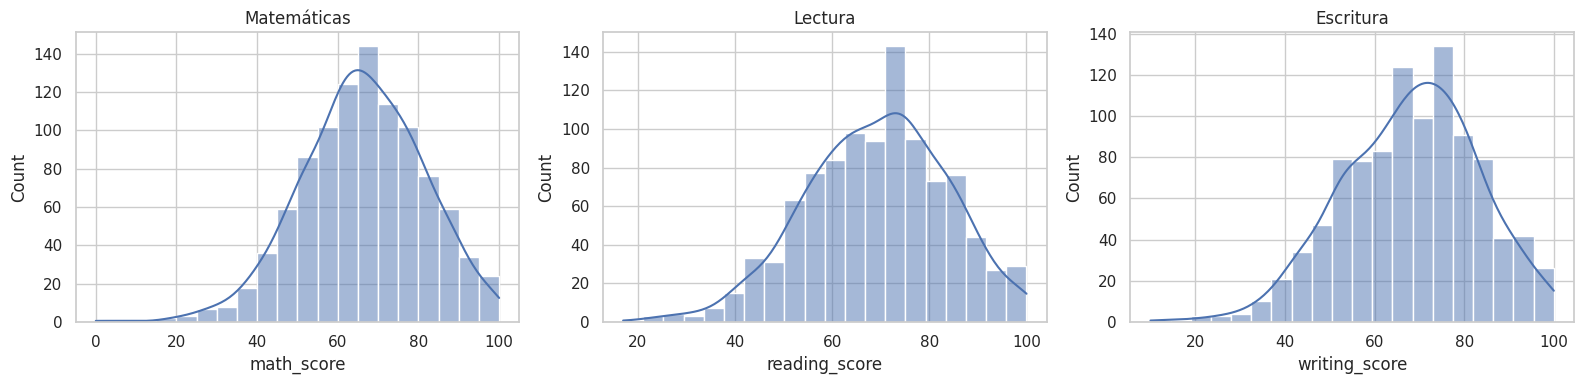

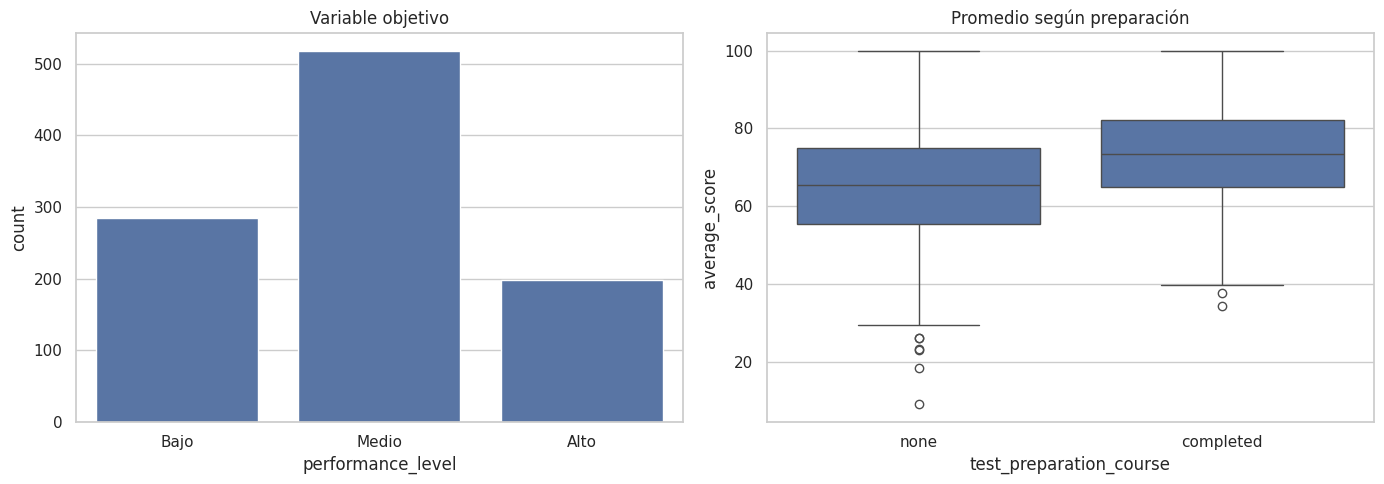

,porcentaje
performance_level,
Bajo,28.5
Medio,51.7
Alto,19.8


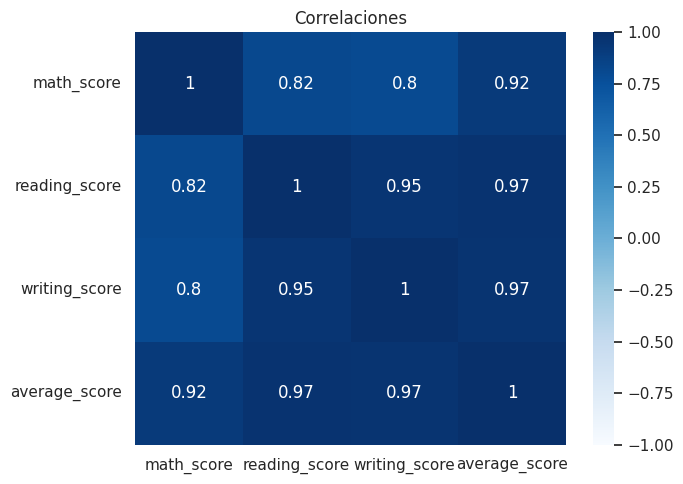

In [5]:
display(df.describe(include="all").T)
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,c,t in zip(ax,scores,["Matemáticas","Lectura","Escritura"]): sns.histplot(df[c],kde=True,bins=20,ax=a); a.set_title(t)
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,2,figsize=(14,5)); order=["Bajo","Medio","Alto"]
sns.countplot(data=df,x=TARGET,order=order,ax=ax[0]); ax[0].set_title("Variable objetivo")
sns.boxplot(data=df,x="test_preparation_course",y="average_score",ax=ax[1]); ax[1].set_title("Promedio según preparación")
plt.tight_layout(); plt.show()
display((df[TARGET].value_counts(normalize=True).reindex(order)*100).round(2).to_frame("porcentaje"))
plt.figure(figsize=(7,5)); sns.heatmap(df[scores+["average_score"]].corr(),annot=True,cmap="Blues",vmin=-1,vmax=1); plt.title("Correlaciones"); plt.tight_layout(); plt.show()

In [6]:
# Interpretación automática y reproducible del EDA
class_counts = df[TARGET].value_counts().reindex(["Bajo", "Medio", "Alto"]).fillna(0).astype(int)
class_pct = (class_counts / class_counts.sum() * 100).round(1)
score_stats = df[scores].agg(["mean", "median", "std", "min", "max"]).round(2)
score_means = score_stats.loc["mean"].sort_values(ascending=False)
score_std = score_stats.loc["std"].sort_values(ascending=False)
corr_scores = df[scores].corr()
pairs = [(a,b,float(corr_scores.loc[a,b])) for i,a in enumerate(scores) for b in scores[i+1:]]
strongest_pair = max(pairs, key=lambda x: abs(x[2]))
prep_means = df.groupby("test_preparation_course", observed=False)["average_score"].mean().sort_values(ascending=False)
prep_gap = float(prep_means.iloc[0] - prep_means.iloc[-1]) if len(prep_means) > 1 else 0.0
imbalance_ratio = float(class_counts.max()/class_counts.min()) if class_counts.min() > 0 else float("inf")

text = f"""
### Interpretación detallada de las gráficas del EDA

#### 1. Histogramas de matemáticas, lectura y escritura
- La media más alta corresponde a **{score_means.index[0].replace('_score','').title()}** con **{score_means.iloc[0]:.2f}** puntos, mientras que la más baja corresponde a **{score_means.index[-1].replace('_score','').title()}** con **{score_means.iloc[-1]:.2f}**.
- La mayor dispersión se observa en **{score_std.index[0].replace('_score','').title()}**, cuya desviación estándar es **{score_std.iloc[0]:.2f}**. Esto significa que sus puntuaciones están más separadas alrededor de la media que las restantes.
- Los histogramas deben leerse observando concentración, asimetría y colas. Una cola extensa indica estudiantes alejados del desempeño central; no implica por sí sola que esos valores sean errores.
- Los valores mínimo y máximo fueron validados entre 0 y 100. Por ello, extremos visibles dentro de ese intervalo se conservan, salvo evidencia adicional de error de captura.

#### 2. Distribución de la variable objetivo
- **Bajo:** {class_counts['Bajo']} estudiantes ({class_pct['Bajo']:.1f}%).
- **Medio:** {class_counts['Medio']} estudiantes ({class_pct['Medio']:.1f}%).
- **Alto:** {class_counts['Alto']} estudiantes ({class_pct['Alto']:.1f}%).
- La relación entre la clase mayoritaria y la minoritaria es **{imbalance_ratio:.2f}:1**. Una razón cercana a 1 representa equilibrio; valores crecientes muestran que `accuracy` puede favorecer a la clase dominante.
- Por esta razón, el proyecto usa **F1 macro** como métrica principal y pesos de clase durante el entrenamiento.

#### 3. Boxplot del promedio según preparación para el examen
- El grupo con mayor promedio es **{prep_means.index[0]}**, con **{prep_means.iloc[0]:.2f}**, frente a **{prep_means.iloc[-1]:.2f}** en **{prep_means.index[-1]}**. La diferencia descriptiva es de **{prep_gap:.2f} puntos**.
- La línea central de cada caja representa la mediana; la caja contiene el 50% central de observaciones; los bigotes y puntos externos muestran dispersión y posibles valores atípicos.
- Esta diferencia es una **asociación descriptiva**, no evidencia causal. El dataset no controla motivación, institución, calidad docente u otras variables que podrían explicar parte de la diferencia.

#### 4. Matriz de correlación
- La relación lineal más alta entre las notas ocurre entre **{strongest_pair[0]}** y **{strongest_pair[1]}**, con **r = {strongest_pair[2]:.3f}**.
- Un coeficiente positivo indica que ambas puntuaciones tienden a aumentar juntas. Valores cercanos a 1 reflejan asociación lineal fuerte; valores cercanos a 0, asociación lineal débil.
- La correlación no demuestra causalidad. Además, estas notas se analizan para comprender el conjunto, pero no se incorporan como entradas del modelo porque construyen directamente la variable objetivo.

> **Lectura global:** el EDA permite justificar el uso de métricas macro, pesos de clase y medidas contra fuga de información. Las conclusiones anteriores se calculan con los datos cargados y se actualizarán automáticamente si cambia el archivo.
"""
display(Markdown(text))


### Interpretación detallada de las gráficas del EDA

#### 1. Histogramas de matemáticas, lectura y escritura
- La media más alta corresponde a **Reading** con **69.17** puntos, mientras que la más baja corresponde a **Math** con **66.09**.
- La mayor dispersión se observa en **Writing**, cuya desviación estándar es **15.20**. Esto significa que sus puntuaciones están más separadas alrededor de la media que las restantes.
- Los histogramas deben leerse observando concentración, asimetría y colas. Una cola extensa indica estudiantes alejados del desempeño central; no implica por sí sola que esos valores sean errores.
- Los valores mínimo y máximo fueron validados entre 0 y 100. Por ello, extremos visibles dentro de ese intervalo se conservan, salvo evidencia adicional de error de captura.

#### 2. Distribución de la variable objetivo
- **Bajo:** 285 estudiantes (28.5%).
- **Medio:** 517 estudiantes (51.7%).
- **Alto:** 198 estudiantes (19.8%).
- La relación entre la clase mayoritaria y la minoritaria es **2.61:1**. Una razón cercana a 1 representa equilibrio; valores crecientes muestran que `accuracy` puede favorecer a la clase dominante.
- Por esta razón, el proyecto usa **F1 macro** como métrica principal y pesos de clase durante el entrenamiento.

#### 3. Boxplot del promedio según preparación para el examen
- El grupo con mayor promedio es **completed**, con **72.67**, frente a **65.04** en **none**. La diferencia descriptiva es de **7.63 puntos**.
- La línea central de cada caja representa la mediana; la caja contiene el 50% central de observaciones; los bigotes y puntos externos muestran dispersión y posibles valores atípicos.
- Esta diferencia es una **asociación descriptiva**, no evidencia causal. El dataset no controla motivación, institución, calidad docente u otras variables que podrían explicar parte de la diferencia.

#### 4. Matriz de correlación
- La relación lineal más alta entre las notas ocurre entre **reading_score** y **writing_score**, con **r = 0.955**.
- Un coeficiente positivo indica que ambas puntuaciones tienden a aumentar juntas. Valores cercanos a 1 reflejan asociación lineal fuerte; valores cercanos a 0, asociación lineal débil.
- La correlación no demuestra causalidad. Además, estas notas se analizan para comprender el conjunto, pero no se incorporan como entradas del modelo porque construyen directamente la variable objetivo.

> **Lectura global:** el EDA permite justificar el uso de métricas macro, pesos de clase y medidas contra fuga de información. Las conclusiones anteriores se calculan con los datos cargados y se actualizarán automáticamente si cambia el archivo.


## 4. Preparación del dataset y pipeline de preprocesamiento

### Objetivo
Transformar las variables categóricas a una representación numérica compatible con una red neuronal y separar correctamente los datos para evitar contaminación entre entrenamiento y evaluación.

### División utilizada
- **70 % entrenamiento:** ajuste de pesos del modelo y del preprocesador.
- **15 % validación:** supervisión del entrenamiento, selección de la mejor época y control de sobreajuste.
- **15 % prueba:** evaluación final una vez terminado el desarrollo.

Se emplea `stratify=y` para conservar aproximadamente la proporción de cada clase en los tres subconjuntos.

### One-Hot Encoding
Las cinco variables de entrada son categóricas. `OneHotEncoder` transforma cada categoría en columnas binarias. `handle_unknown="ignore"` permite que el pipeline no falle si durante inferencia aparece una categoría no vista en entrenamiento.

### Regla crítica
El `ColumnTransformer` se ajusta **exclusivamente con `X_train`**; posteriormente solo transforma validación y prueba. Ajustarlo antes de dividir constituiría otra forma de fuga de información.

> **Resultado esperado:** matrices NumPy `float32` listas para el MLP, manteniendo el conjunto de prueba aislado.


In [7]:
X=df[FEATURES].copy(); le=LabelEncoder(); y=le.fit_transform(df[TARGET])
class_counts_before_split = pd.Series(y).value_counts()
assert class_counts_before_split.min() >= 7, (
    "Cada clase debe tener al menos 7 registros para realizar dos divisiones estratificadas."
)
X_train,X_tmp,y_train,y_tmp=train_test_split(X,y,test_size=.30,stratify=y,random_state=SEED)
X_val,X_test,y_val,y_test=train_test_split(X_tmp,y_tmp,test_size=.50,stratify=y_tmp,random_state=SEED)
assert not(set(X_train.index)&set(X_val.index)) and not(set(X_train.index)&set(X_test.index)) and not(set(X_val.index)&set(X_test.index))
total = len(X)
assert len(X_train)+len(X_val)+len(X_test) == total
assert np.isclose(len(X_train)/total, .70, atol=.01)
assert np.isclose(len(X_val)/total, .15, atol=.01)
assert np.isclose(len(X_test)/total, .15, atol=.01)
try: ohe=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
except TypeError: ohe=OneHotEncoder(handle_unknown="ignore",sparse=False)
preprocessor=ColumnTransformer([("cat",ohe,FEATURES)],remainder="drop",verbose_feature_names_out=False)
X_train_p=np.asarray(preprocessor.fit_transform(X_train),dtype=np.float32)
X_val_p=np.asarray(preprocessor.transform(X_val),dtype=np.float32); X_test_p=np.asarray(preprocessor.transform(X_test),dtype=np.float32)
print("Clases:",dict(zip(le.classes_,le.transform(le.classes_))))
print("Train/Val/Test:",len(X_train),len(X_val),len(X_test),"| Entrada MLP:",X_train_p.shape)

Clases: {'Alto': np.int64(0), 'Bajo': np.int64(1), 'Medio': np.int64(2)}
Train/Val/Test: 700 150 150 | Entrada MLP: (700, 17)


In [8]:
# Verificación e interpretación de la partición y del preprocesamiento
split_table = pd.DataFrame({
    "Entrenamiento": pd.Series(y_train).value_counts(normalize=True),
    "Validación": pd.Series(y_val).value_counts(normalize=True),
    "Prueba": pd.Series(y_test).value_counts(normalize=True)
}).fillna(0)
split_table.index = le.inverse_transform(split_table.index.astype(int))
split_table = (split_table * 100).round(1)

text = f"""
### Interpretación de la preparación del pipeline

- El conjunto de entrenamiento contiene **{len(X_train)} registros**, validación **{len(X_val)}** y prueba **{len(X_test)}**.
- La estratificación conserva proporciones similares por clase. Las diferencias restantes son producto del redondeo inherente a una muestra finita.
- Las cinco variables originales se convierten en **{X_train_p.shape[1]} columnas binarias** mediante One-Hot Encoding.
- `handle_unknown="ignore"` evita errores técnicos ante categorías nuevas, pero una categoría desconocida quedará representada con ceros en el bloque correspondiente. Si esto ocurre con frecuencia en producción, el modelo debe revisarse o reentrenarse.
- No se aplica `StandardScaler` porque las entradas resultantes son indicadores 0/1. El preprocesador fue ajustado únicamente con entrenamiento, protegiendo validación y prueba frente a fuga de información.

**Distribución porcentual por partición:**
"""
display(Markdown(text))
display(split_table)


### Interpretación de la preparación del pipeline

- El conjunto de entrenamiento contiene **700 registros**, validación **150** y prueba **150**.
- La estratificación conserva proporciones similares por clase. Las diferencias restantes son producto del redondeo inherente a una muestra finita.
- Las cinco variables originales se convierten en **17 columnas binarias** mediante One-Hot Encoding.
- `handle_unknown="ignore"` evita errores técnicos ante categorías nuevas, pero una categoría desconocida quedará representada con ceros en el bloque correspondiente. Si esto ocurre con frecuencia en producción, el modelo debe revisarse o reentrenarse.
- No se aplica `StandardScaler` porque las entradas resultantes son indicadores 0/1. El preprocesador fue ajustado únicamente con entrenamiento, protegiendo validación y prueba frente a fuga de información.

**Distribución porcentual por partición:**


,Entrenamiento,Validación,Prueba
Medio,51.7,52.0,51.3
Bajo,28.4,28.7,28.7
Alto,19.9,19.3,20.0


## 5. Modelado: líneas base y arquitectura neuronal MLP

### ¿Por qué comparar modelos?
Una arquitectura profunda no debe considerarse buena solamente por utilizar redes neuronales. Debe compararse contra referencias más simples para saber si realmente aprende información útil.

### Línea base 1: DummyClassifier
Predice siempre la clase más frecuente. Representa el rendimiento mínimo que un modelo útil debería superar.

### Línea base 2: Regresión logística
Es un clasificador lineal sólido para datos tabulares codificados. Se usa `class_weight="balanced"` para reducir el efecto del posible desbalance.

### Modelo principal: MLP profundo
Arquitectura:

`Entrada -> Dense(128) -> BatchNorm -> Dropout(0.30) -> Dense(64) -> BatchNorm -> Dropout(0.20) -> Dense(32) -> Softmax(3)`

- **ReLU:** introduce no linealidad.
- **Batch Normalization:** estabiliza las activaciones durante el entrenamiento.
- **Dropout:** apaga aleatoriamente neuronas para reducir sobreajuste.
- **L2:** penaliza pesos excesivamente grandes.
- **Softmax:** genera una distribución de probabilidad entre Bajo, Medio y Alto.
- **Adam:** optimiza los pesos con tasa inicial de aprendizaje de 0.001.
- **Sparse categorical crossentropy:** función de pérdida apropiada para etiquetas enteras multiclase.

También se calculan pesos balanceados para que los errores de las clases menos frecuentes tengan mayor relevancia.

> **Resultado esperado:** tres modelos comparables bajo la misma partición de datos.


In [9]:
def metrics(name,yt,yp):
    return {"modelo":name,"accuracy":accuracy_score(yt,yp),"precision_macro":precision_score(yt,yp,average="macro",zero_division=0),"recall_macro":recall_score(yt,yp,average="macro",zero_division=0),"f1_macro":f1_score(yt,yp,average="macro",zero_division=0)}
results=[]
dummy=DummyClassifier(strategy="most_frequent",random_state=SEED).fit(X_train_p,y_train); results.append(metrics("Dummy",y_test,dummy.predict(X_test_p)))
logreg=LogisticRegression(max_iter=2000,class_weight="balanced",random_state=SEED).fit(X_train_p,y_train); results.append(metrics("Regresión logística",y_test,logreg.predict(X_test_p)))
classes=np.unique(y_train); w=compute_class_weight("balanced",classes=classes,y=y_train); class_weight={int(c):float(v) for c,v in zip(classes,w)}
def build_model(n_in,n_out):
    m=Sequential([Input((n_in,)),Dense(128,activation="relu",kernel_regularizer=l2(1e-3)),BatchNormalization(),Dropout(.30),Dense(64,activation="relu",kernel_regularizer=l2(1e-3)),BatchNormalization(),Dropout(.20),Dense(32,activation="relu"),Dense(n_out,activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
model=build_model(X_train_p.shape[1],len(le.classes_)); model.summary(); print("Pesos:",class_weight)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,507 (52.76 KB)

 Trainable params: 13,123 (51.26 KB)

 Non-trainable params: 384 (1.50 KB)

Pesos: {0: 1.6786570743405276, 1: 1.1725293132328307, 2: 0.6445672191528545}


## 6. Entrenamiento y control de sobreajuste

### Objetivo
Entrenar el MLP sin escoger arbitrariamente el número de épocas y conservar automáticamente la versión con mejor generalización sobre validación.

### Estrategia
- Máximo de **150 épocas**.
- `batch_size=32`.
- **EarlyStopping:** detiene el proceso si `val_loss` deja de mejorar durante 15 épocas y restaura los mejores pesos.
- **ReduceLROnPlateau:** reduce a la mitad el *learning rate* después de 5 épocas sin mejora, hasta un mínimo de `1e-6`.
- **ModelCheckpoint:** guarda la mejor red en `models/best_mlp_model.keras`.

### Curvas de aprendizaje
Se grafican `loss` y `accuracy` de entrenamiento y validación. Una separación creciente donde entrenamiento mejora pero validación empeora es una señal típica de sobreajuste.

> **Resultado esperado:** obtener la mejor época según `val_loss`, no necesariamente la última de las 150 posibles.


Epoch 1/150
16/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2974 - loss: 1.5741
Epoch 1: val_loss improved from None to 1.18793, saving model to /content/models/best_mlp_model.keras

Epoch 1: finished saving model to /content/models/best_mlp_model.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.3171 - loss: 1.4819 - val_accuracy: 0.4933 - val_loss: 1.1879 - learning_rate: 0.0010
Epoch 2/150
19/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4089 - loss: 1.1883
Epoch 2: val_loss improved from 1.18793 to 1.16507, saving model to /content/models/best_mlp_model.keras

Epoch 2: finished saving model to /content/models/best_mlp_model.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.3900 - loss: 1.2268 - val_accuracy: 0.5133 - val_loss: 1.1651 - learning_rate: 0.0010
Epoch 3/150
20/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4130 - loss: 1.1648
Epoch 3: val_loss did not improve from 1.16507
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.4257 - loss: 

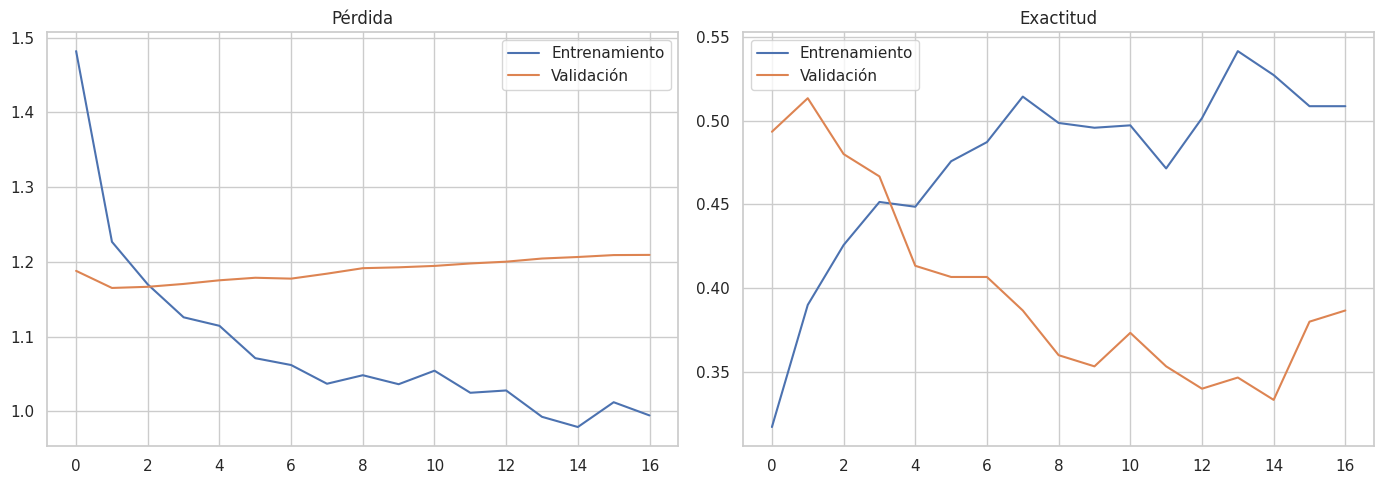

In [10]:
CHECKPOINT=MODEL_DIR/"best_mlp_model.keras"
callbacks=[EarlyStopping(monitor="val_loss",patience=15,restore_best_weights=True,verbose=1),ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=5,min_lr=1e-6,verbose=1),ModelCheckpoint(CHECKPOINT,monitor="val_loss",save_best_only=True,verbose=1)]
history=model.fit(X_train_p,y_train,validation_data=(X_val_p,y_val),epochs=150,batch_size=32,class_weight=class_weight,callbacks=callbacks,verbose=1)
model=keras.models.load_model(CHECKPOINT)
h=pd.DataFrame(history.history); best_epoch=int(h.val_loss.idxmin()+1); print("Mejor época:",best_epoch)
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].plot(h.loss,label="Entrenamiento"); ax[0].plot(h.val_loss,label="Validación"); ax[0].set_title("Pérdida"); ax[0].legend()
ax[1].plot(h.accuracy,label="Entrenamiento"); ax[1].plot(h.val_accuracy,label="Validación"); ax[1].set_title("Exactitud"); ax[1].legend()
plt.tight_layout(); plt.savefig(ASSET_DIR/"learning_curves.png",dpi=180,bbox_inches="tight"); plt.show()

In [11]:
# Diagnóstico automático de las curvas de aprendizaje
min_val_loss = float(h["val_loss"].min())
train_loss_best = float(h.loc[best_epoch-1, "loss"])
val_acc_best = float(h.loc[best_epoch-1, "val_accuracy"])
train_acc_best = float(h.loc[best_epoch-1, "accuracy"])
gap_acc = train_acc_best - val_acc_best
last_epoch = len(h)
if gap_acc > 0.10:
    diagnosis = "Existe una brecha relevante a favor del entrenamiento, compatible con sobreajuste."
elif gap_acc < -0.03:
    diagnosis = "La validación supera al entrenamiento; puede ocurrir por Dropout y por variabilidad de una muestra pequeña."
else:
    diagnosis = "Las exactitudes de entrenamiento y validación son relativamente cercanas, sin una señal extrema de sobreajuste en la mejor época."
text=f"""
### Interpretación detallada de las curvas de aprendizaje

- El entrenamiento ejecutó **{last_epoch} épocas** y la mejor época según `val_loss` fue la **{best_epoch}**.
- En esa época, `loss` de entrenamiento fue **{train_loss_best:.4f}** y el mínimo `val_loss` fue **{min_val_loss:.4f}**.
- La exactitud de entrenamiento fue **{train_acc_best:.3f}** y la de validación **{val_acc_best:.3f}**, con una brecha de **{gap_acc:.3f}**.
- **Diagnóstico:** {diagnosis}
- La curva de pérdida es prioritaria para seleccionar el checkpoint porque considera no solo aciertos, sino también la calidad probabilística y la confianza de las predicciones.
- Si `loss` de entrenamiento continúa descendiendo mientras `val_loss` aumenta durante varias épocas, el modelo memoriza patrones particulares. `EarlyStopping`, Dropout y L2 mitigan ese riesgo.
- Si ambas curvas permanecen altas y casi no mejoran, habría subajuste: las variables disponibles o la capacidad del modelo serían insuficientes.

> El archivo `best_mlp_model.keras` corresponde a la mejor `val_loss`, no necesariamente a la última época ejecutada.
"""
display(Markdown(text))


### Interpretación detallada de las curvas de aprendizaje

- El entrenamiento ejecutó **17 épocas** y la mejor época según `val_loss` fue la **2**.
- En esa época, `loss` de entrenamiento fue **1.2268** y el mínimo `val_loss` fue **1.1651**.
- La exactitud de entrenamiento fue **0.390** y la de validación **0.513**, con una brecha de **-0.123**.
- **Diagnóstico:** La validación supera al entrenamiento; puede ocurrir por Dropout y por variabilidad de una muestra pequeña.
- La curva de pérdida es prioritaria para seleccionar el checkpoint porque considera no solo aciertos, sino también la calidad probabilística y la confianza de las predicciones.
- Si `loss` de entrenamiento continúa descendiendo mientras `val_loss` aumenta durante varias épocas, el modelo memoriza patrones particulares. `EarlyStopping`, Dropout y L2 mitigan ese riesgo.
- Si ambas curvas permanecen altas y casi no mejoran, habría subajuste: las variables disponibles o la capacidad del modelo serían insuficientes.

> El archivo `best_mlp_model.keras` corresponde a la mejor `val_loss`, no necesariamente a la última época ejecutada.


## 7. Evaluación cuantitativa del modelo

### Objetivo
Medir el desempeño sobre datos que el modelo no utilizó para aprender ni para seleccionar su mejor época.

### Métricas
- **Loss:** valor de la función de pérdida. Menor es mejor.
- **Accuracy:** proporción total de predicciones correctas.
- **Precision macro:** promedio de precisión de las tres clases.
- **Recall macro:** promedio de sensibilidad de las tres clases.
- **F1 macro:** media del F1 de cada clase dando el mismo peso a Bajo, Medio y Alto. Es la métrica principal del proyecto.

### Matriz de confusión
Las filas corresponden a las clases reales y las columnas a las predicciones. La diagonal contiene los aciertos; las celdas fuera de la diagonal muestran qué niveles tiende a confundir el modelo.

### Criterio de selección
No se declarará automáticamente al MLP como ganador. Se compara su `F1 macro` y `accuracy` contra Dummy y regresión logística. Si una línea base obtiene mejor F1 macro, ese resultado debe documentarse de forma transparente.

> **Resultado esperado:** métricas finales honestas, matriz de confusión y gráfica comparativa listas para utilizar en la sustentación y el póster.


,modelo,accuracy,precision_macro,recall_macro,f1_macro,loss
0,Regresión logística,0.4467,0.4657,0.5011,0.4484,NaN
1,MLP profundo,0.5133,0.5057,0.3402,0.2549,1.1474
2,Dummy,0.5133,0.1711,0.3333,0.2261,NaN


              precision    recall  f1-score   support

        Alto       0.00      0.00      0.00        30
        Bajo       1.00      0.05      0.09        43
       Medio       0.52      0.97      0.68        77

    accuracy                           0.51       150
   macro avg       0.51      0.34      0.25       150
weighted avg       0.55      0.51      0.37       150



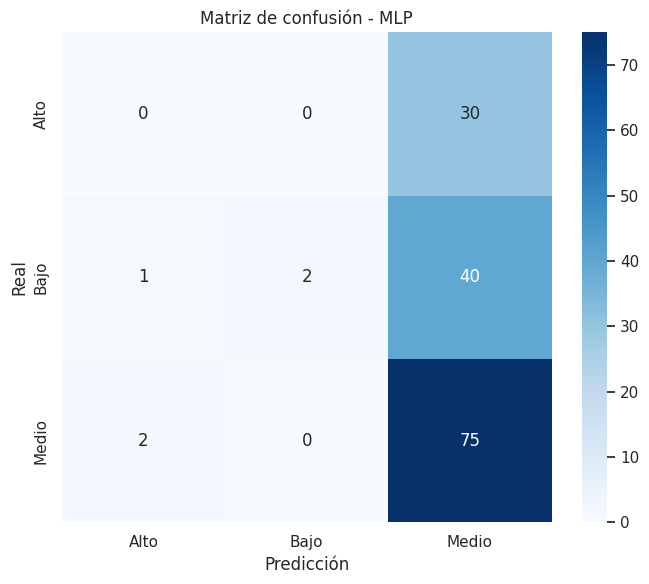

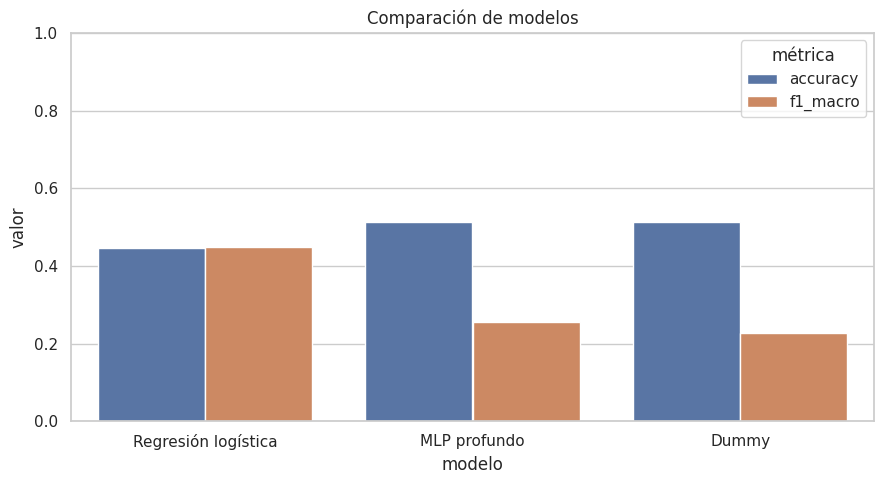

In [12]:
test_loss,test_accuracy=model.evaluate(X_test_p,y_test,verbose=0); probs=model.predict(X_test_p,verbose=0); y_pred=probs.argmax(1)
r=metrics("MLP profundo",y_test,y_pred); r["loss"]=float(test_loss); results.append(r)
comparison=pd.DataFrame(results).sort_values("f1_macro",ascending=False).reset_index(drop=True); display(comparison.round(4))
print(classification_report(y_test,y_pred,labels=np.arange(len(le.classes_)),target_names=le.classes_,zero_division=0))
cm=confusion_matrix(y_test,y_pred,labels=np.arange(len(le.classes_)))
plt.figure(figsize=(7,6)); sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=le.classes_,yticklabels=le.classes_); plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión - MLP"); plt.tight_layout(); plt.savefig(ASSET_DIR/"confusion_matrix.png",dpi=180,bbox_inches="tight"); plt.show()
p=comparison.melt(id_vars="modelo",value_vars=["accuracy","f1_macro"],var_name="métrica",value_name="valor")
plt.figure(figsize=(9,5)); sns.barplot(data=p,x="modelo",y="valor",hue="métrica"); plt.ylim(0,1); plt.title("Comparación de modelos"); plt.tight_layout(); plt.savefig(ASSET_DIR/"model_comparison.png",dpi=180,bbox_inches="tight"); plt.show()

In [13]:
# Interpretación automática de métricas, matriz de confusión y comparación
report_dict = classification_report(y_test, y_pred, labels=np.arange(len(le.classes_)), target_names=le.classes_, zero_division=0, output_dict=True)
summary_rows=[]
for name in le.classes_:
    d=report_dict[name]
    summary_rows.append({"clase":name,"precision":d["precision"],"recall":d["recall"],"f1":d["f1-score"],"soporte":int(d["support"])})
class_metrics=pd.DataFrame(summary_rows).set_index("clase")
best_model_name=comparison.iloc[0]["modelo"]
best_f1=float(comparison.iloc[0]["f1_macro"])
mlp_f1=float(comparison.loc[comparison.modelo=="MLP profundo","f1_macro"].iloc[0])
dummy_f1=float(comparison.loc[comparison.modelo=="Dummy","f1_macro"].iloc[0])
correct=int(np.trace(cm)); total=int(cm.sum())
worst_class=class_metrics["f1"].idxmin(); best_class=class_metrics["f1"].idxmax()
off=cm.copy(); np.fill_diagonal(off,0); ri,ci=np.unravel_index(np.argmax(off),off.shape)
confusion_count=int(off[ri,ci])

text=f"""
### Interpretación detallada de las métricas finales

#### Rendimiento global
- El MLP obtuvo **accuracy = {test_accuracy:.3f}**, es decir, acertó **{correct} de {total}** casos del conjunto de prueba.
- Su **F1 macro = {mlp_f1:.3f}** resume el equilibrio entre precisión y recall de las tres clases, otorgando el mismo peso a cada una.
- El valor de pérdida fue **{test_loss:.4f}**. A diferencia de accuracy, la pérdida penaliza también predicciones probabilísticas incorrectas con alta confianza.
- El mejor modelo por F1 macro fue **{best_model_name}**, con **{best_f1:.3f}**. El MLP supera al Dummy por **{mlp_f1-dummy_f1:.3f} puntos de F1 macro**.

#### Significado de las métricas por clase
- **Precision:** de todas las predicciones realizadas para una clase, indica qué proporción fue correcta. Precisión baja implica falsos positivos frecuentes.
- **Recall:** de todos los casos reales de una clase, indica qué proporción fue detectada. Recall bajo implica estudiantes de esa clase que el sistema no identifica.
- **F1:** media armónica entre precision y recall. Solo es alta cuando ambas son razonablemente altas.
- La clase mejor reconocida por F1 fue **{best_class}** y la más difícil fue **{worst_class}**. Esto debe considerarse antes de cualquier uso práctico.

#### Lectura de la matriz de confusión
- La diagonal suma **{correct} aciertos**; las demás celdas son errores.
- La confusión más frecuente fue clasificar **{le.classes_[ri]}** como **{le.classes_[ci]}**, con **{confusion_count} casos**.
- Si las confusiones se concentran entre niveles adyacentes, el modelo está captando parcialmente el orden académico, aunque la clasificación siga siendo incorrecta. Una confusión entre Bajo y Alto sería más crítica.

#### Comparación con las líneas base
- `DummyClassifier` establece el mínimo de referencia; superarlo demuestra que existe señal predictiva más allá de elegir la clase mayoritaria.
- La regresión logística evalúa si relaciones lineales simples son suficientes. Si iguala o supera al MLP, debe preferirse por simplicidad, estabilidad e interpretabilidad.
- Una diferencia pequeña en este único split no prueba superioridad general. Para una conclusión más robusta se recomienda validación cruzada repetida o evaluación en una cohorte externa.

> **Conclusión de evaluación:** reporte el modelo ganador según F1 macro y mantenga visibles las métricas por clase. No debe afirmarse que el MLP es superior si la tabla comparativa no lo respalda.
"""
display(Markdown(text))
display(class_metrics.round(3))


### Interpretación detallada de las métricas finales

#### Rendimiento global
- El MLP obtuvo **accuracy = 0.513**, es decir, acertó **77 de 150** casos del conjunto de prueba.
- Su **F1 macro = 0.255** resume el equilibrio entre precisión y recall de las tres clases, otorgando el mismo peso a cada una.
- El valor de pérdida fue **1.1474**. A diferencia de accuracy, la pérdida penaliza también predicciones probabilísticas incorrectas con alta confianza.
- El mejor modelo por F1 macro fue **Regresión logística**, con **0.448**. El MLP supera al Dummy por **0.029 puntos de F1 macro**.

#### Significado de las métricas por clase
- **Precision:** de todas las predicciones realizadas para una clase, indica qué proporción fue correcta. Precisión baja implica falsos positivos frecuentes.
- **Recall:** de todos los casos reales de una clase, indica qué proporción fue detectada. Recall bajo implica estudiantes de esa clase que el sistema no identifica.
- **F1:** media armónica entre precision y recall. Solo es alta cuando ambas son razonablemente altas.
- La clase mejor reconocida por F1 fue **Medio** y la más difícil fue **Alto**. Esto debe considerarse antes de cualquier uso práctico.

#### Lectura de la matriz de confusión
- La diagonal suma **77 aciertos**; las demás celdas son errores.
- La confusión más frecuente fue clasificar **Bajo** como **Medio**, con **40 casos**.
- Si las confusiones se concentran entre niveles adyacentes, el modelo está captando parcialmente el orden académico, aunque la clasificación siga siendo incorrecta. Una confusión entre Bajo y Alto sería más crítica.

#### Comparación con las líneas base
- `DummyClassifier` establece el mínimo de referencia; superarlo demuestra que existe señal predictiva más allá de elegir la clase mayoritaria.
- La regresión logística evalúa si relaciones lineales simples son suficientes. Si iguala o supera al MLP, debe preferirse por simplicidad, estabilidad e interpretabilidad.
- Una diferencia pequeña en este único split no prueba superioridad general. Para una conclusión más robusta se recomienda validación cruzada repetida o evaluación en una cohorte externa.

> **Conclusión de evaluación:** reporte el modelo ganador según F1 macro y mantenga visibles las métricas por clase. No debe afirmarse que el MLP es superior si la tabla comparativa no lo respalda.


,precision,recall,f1,soporte
clase,,,,
Alto,0.000,0.000,0.000,30
Bajo,1.000,0.047,0.089,43
Medio,0.517,0.974,0.676,77


## 8. Análisis de errores, persistencia e inferencia

### 8.1 Análisis de errores
Se construye una tabla con clase real, clase predicha, confianza máxima y condición de acierto. Revisar errores de alta confianza ayuda a identificar patrones donde el modelo se equivoca de forma sistemática.

### 8.2 Persistencia
Se guardan por separado:
- `best_mlp_model.keras`: pesos y arquitectura de la red.
- `preprocessor.joblib`: exactamente el One-Hot Encoding aprendido.
- `label_encoder.joblib`: correspondencia entre índices y clases.
- `metrics.json`: cifras finales para Streamlit, póster y video.
- `training_history.json`: historia de entrenamiento.
- `test_predictions.csv`: predicciones de prueba para auditoría.

Guardar el preprocesador es tan importante como guardar la red. Streamlit debe aplicar **exactamente las mismas transformaciones** utilizadas durante entrenamiento.

### 8.3 Prueba de inferencia
La función `predict_student()` simula lo que hará posteriormente `app.py`: carga los artefactos desde disco, crea un registro, lo transforma, ejecuta la red y devuelve clase, confianza y probabilidades.

> **Resultado esperado:** comprobar de extremo a extremo que los artefactos guardados son suficientes para desplegar el modelo sin volver a entrenarlo.


In [14]:
errors=X_test.reset_index(drop=True).copy(); errors["real"]=le.inverse_transform(y_test); errors["predicho"]=le.inverse_transform(y_pred); errors["confianza"]=probs.max(1); errors["correcto"]=errors.real==errors.predicho
display(errors.loc[~errors.correcto].sort_values("confianza",ascending=False).head(15))
joblib.dump(preprocessor,MODEL_DIR/"preprocessor.joblib"); joblib.dump(le,MODEL_DIR/"label_encoder.joblib"); joblib.dump(logreg,MODEL_DIR/"logistic_baseline.joblib")
with open(MODEL_DIR/"training_history.json","w",encoding="utf-8") as f: json.dump({k:[float(x) for x in v] for k,v in history.history.items()},f,ensure_ascii=False,indent=2)
comparison_records = comparison.fillna(0).to_dict("records")
assert len(comparison_records) == 3, "comparison debe contener Dummy, Regresión logística y MLP"
for row in comparison_records:
    assert "modelo" in row and "f1_macro" in row
    assert np.isfinite(float(row["f1_macro"])), f"F1 no finito: {row}"

numeric_metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(f1_score(y_test,y_pred,average="macro",zero_division=0)),
}
for name, value in numeric_metrics.items():
    assert np.isfinite(value), f"{name} no es finito: {value}"

runtime_versions = {
    "python": sys.version.split()[0],
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "joblib": joblib.__version__,
}

report={
    "seed":SEED,
    "features":FEATURES,
    "excluded_for_leakage":LEAKAGE,
    "class_names":le.classes_.tolist(),
    "deployed_model":"MLP profundo",
    "model_artifact":"best_mlp_model.keras",
    "selection_metric":"f1_macro",
    "best_epoch":best_epoch,
    "test_loss":numeric_metrics["test_loss"],
    "test_accuracy":numeric_metrics["test_accuracy"],
    "test_f1_macro":numeric_metrics["test_f1_macro"],
    "comparison":comparison_records,
    "runtime_versions":runtime_versions
}
required_metrics={"seed","features","class_names","best_epoch","test_loss","test_accuracy","test_f1_macro","comparison"}
assert required_metrics.issubset(report), f"metrics.json incompleto: {required_metrics-set(report)}"
with open(MODEL_DIR/"metrics.json","w",encoding="utf-8") as f: json.dump(report,f,ensure_ascii=False,indent=2)
out=errors.copy()
for i,n in enumerate(le.classes_): out[f"prob_{n.lower()}"]=probs[:,i]
out.to_csv(DATA_DIR/"test_predictions.csv",index=False)
def predict_student(record):
    pp=joblib.load(MODEL_DIR/"preprocessor.joblib"); enc=joblib.load(MODEL_DIR/"label_encoder.joblib"); m=keras.models.load_model(CHECKPOINT)
    frame=pd.DataFrame([record]); missing=set(FEATURES)-set(frame.columns)
    if missing: raise ValueError(f"Faltan variables: {sorted(missing)}")
    pr=m.predict(np.asarray(pp.transform(frame[FEATURES]),dtype=np.float32),verbose=0)[0]; idx=int(pr.argmax())
    return {"nivel_predicho":enc.inverse_transform([idx])[0],"confianza":float(pr[idx]),"probabilidades":{n:float(v) for n,v in zip(enc.classes_,pr)}}
example={"gender":"female","race_ethnicity":"group C","parental_level_of_education":"some college","lunch":"standard","test_preparation_course":"completed"}
print(json.dumps(predict_student(example),ensure_ascii=False,indent=2))
for p in sorted([*MODEL_DIR.iterdir(),*ASSET_DIR.iterdir(),DATA_DIR/"education.db",DATA_DIR/"test_predictions.csv"]): print(p)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,real,predicho,confianza,correcto
25,female,group D,associate's degree,standard,none,Alto,Medio,0.476217,False
75,female,group C,associate's degree,standard,none,Bajo,Medio,0.457343,False
69,female,group C,associate's degree,standard,none,Bajo,Medio,0.457343,False
48,female,group C,associate's degree,standard,none,Alto,Medio,0.457343,False
65,female,group D,high school,free/reduced,none,Bajo,Medio,0.443944,False
18,female,group D,associate's degree,standard,completed,Alto,Medio,0.442321,False
29,female,group D,bachelor's degree,standard,none,Alto,Medio,0.440125,False
116,female,group B,high school,free/reduced,none,Bajo,Medio,0.438083,False
36,female,group B,high school,standard,none,Bajo,Medio,0.431947,False
49,female,group B,high school,standard,none,Bajo,Medio,0.431947,False


{
  "nivel_predicho": "Medio",
  "confianza": 0.40758511424064636,
  "probabilidades": {
    "Alto": 0.36370810866355896,
    "Bajo": 0.22870679199695587,
    "Medio": 0.40758511424064636
  }
}
/content/assets/confusion_matrix.png
/content/assets/learning_curves.png
/content/assets/model_comparison.png
/content/data/education.db
/content/data/test_predictions.csv
/content/models/best_mlp_model.keras
/content/models/label_encoder.joblib
/content/models/logistic_baseline.joblib
/content/models/metrics.json
/content/models/preprocessor.joblib
/content/models/training_history.json


In [15]:
# Interpretación del análisis de errores y confianza
n_errors=int((~errors["correcto"]).sum())
error_rate=n_errors/len(errors)
mean_conf_correct=float(errors.loc[errors.correcto,"confianza"].mean()) if errors.correcto.any() else float("nan")
mean_conf_error=float(errors.loc[~errors.correcto,"confianza"].mean()) if (~errors.correcto).any() else 0.0
high_conf_errors=int(((~errors.correcto)&(errors.confianza>=.80)).sum())
text=f"""
### Interpretación del análisis de errores

- Se encontraron **{n_errors} errores de {len(errors)} casos**, equivalentes a una tasa de error de **{error_rate:.1%}**.
- La confianza media en los aciertos fue **{mean_conf_correct:.3f}** y en los errores **{mean_conf_error:.3f}**.
- Hubo **{high_conf_errors} errores con confianza igual o superior al 80%**. Estos casos son especialmente importantes porque el modelo no solo falla, sino que lo hace con elevada seguridad.
- La confianza de Softmax no debe interpretarse automáticamente como probabilidad perfectamente calibrada. Para decisiones sensibles sería necesario evaluar calibración con Brier score, curva de calibración o `Expected Calibration Error`.
- La tabla permite buscar categorías recurrentes en los errores. Sin embargo, con un conjunto de prueba pequeño no conviene generalizar a grupos completos a partir de pocos registros.

> **Uso práctico:** Streamlit debe presentar la distribución completa de probabilidades y una advertencia, no únicamente la clase ganadora.
"""
display(Markdown(text))


### Interpretación del análisis de errores

- Se encontraron **73 errores de 150 casos**, equivalentes a una tasa de error de **48.7%**.
- La confianza media en los aciertos fue **0.408** y en los errores **0.406**.
- Hubo **0 errores con confianza igual o superior al 80%**. Estos casos son especialmente importantes porque el modelo no solo falla, sino que lo hace con elevada seguridad.
- La confianza de Softmax no debe interpretarse automáticamente como probabilidad perfectamente calibrada. Para decisiones sensibles sería necesario evaluar calibración con Brier score, curva de calibración o `Expected Calibration Error`.
- La tabla permite buscar categorías recurrentes en los errores. Sin embargo, con un conjunto de prueba pequeño no conviene generalizar a grupos completos a partir de pocos registros.

> **Uso práctico:** Streamlit debe presentar la distribución completa de probabilidades y una advertencia, no únicamente la clase ganadora.


## 9. Conclusiones, trazabilidad del objetivo y limitaciones

### Coherencia con el objetivo
El objetivo del notebook es evaluar si las cinco variables socioeducativas disponibles aportan señal predictiva para clasificar el nivel de rendimiento y determinar, mediante comparación objetiva, si el MLP ofrece ventaja frente a modelos más simples. Por ello, la conclusión final debe depender de las métricas calculadas y no de la arquitectura elegida inicialmente.

### Criterios para concluir
1. **Utilidad mínima:** el modelo candidato debe superar a `DummyClassifier` en F1 macro.
2. **Valor de la red neuronal:** solo se afirmará que el MLP aporta ventaja si supera a regresión logística en el conjunto de prueba; una diferencia pequeña en un único split se describirá como evidencia preliminar, no definitiva.
3. **Desempeño por clase:** además del promedio global, se revisarán precision, recall y F1 de Bajo, Medio y Alto.
4. **Generalización:** las curvas de aprendizaje y la brecha entrenamiento-validación se utilizarán para describir posibles señales de sobreajuste o subajuste.
5. **Uso práctico:** las probabilidades Softmax se presentarán como confianza del modelo, no como probabilidades perfectamente calibradas.

### Limitaciones
- El dataset tiene alrededor de 1.000 observaciones y únicamente cinco atributos de alerta temprana.
- La etiqueta Bajo/Medio/Alto se deriva del promedio de las tres notas; estas notas se excluyen correctamente de las entradas para prevenir fuga de información.
- Un único split 70/15/15 ofrece una estimación puntual. Para afirmar estabilidad se recomienda validación cruzada repetida y, para generalización institucional, una cohorte externa.
- Las asociaciones observadas no demuestran causalidad.
- Este prototipo no debe automatizar decisiones de exclusión, sanción o etiquetamiento de estudiantes.

### Conexión con Streamlit
`app.py` deberá cargar `preprocessor.joblib`, `label_encoder.joblib` y `best_mlp_model.keras` (mejor checkpoint del MLP por `val_loss`), capturar exactamente las cinco variables definidas en `FEATURES`, mostrar la distribución completa de confianza por clase y comunicar las limitaciones anteriores.

> **Nota:** la siguiente celda genera las conclusiones cuantitativas finales usando los resultados reales de esta ejecución. De esta manera, objetivos, resultados y conclusiones permanecen alineados aunque cambie el dataset o el entrenamiento.


In [16]:
# Conclusiones cuantitativas derivadas de los resultados, sin cifras predefinidas
mlp_row = comparison.loc[comparison["modelo"] == "MLP profundo"].iloc[0]
log_row = comparison.loc[comparison["modelo"] == "Regresión logística"].iloc[0]
dum_row = comparison.loc[comparison["modelo"] == "Dummy"].iloc[0]
mlp_vs_log = float(mlp_row["f1_macro"] - log_row["f1_macro"])
mlp_vs_dummy = float(mlp_row["f1_macro"] - dum_row["f1_macro"])

if mlp_vs_log > 0.02:
    architecture_conclusion = f"El MLP supera a la regresión logística en {mlp_vs_log:.3f} puntos de F1 macro en este conjunto de prueba; existe evidencia preliminar de una ventaja de la arquitectura neuronal para este split."
elif mlp_vs_log >= -0.02:
    architecture_conclusion = f"MLP y regresión logística presentan una diferencia pequeña ({mlp_vs_log:+.3f} en F1 macro). Con este experimento no hay evidencia suficiente para afirmar una ventaja práctica clara del MLP."
else:
    architecture_conclusion = f"El MLP queda {abs(mlp_vs_log):.3f} puntos de F1 macro por debajo de la regresión logística. En este experimento, la arquitectura profunda no aporta una mejora predictiva frente al modelo lineal."

if mlp_vs_dummy > 0:
    baseline_conclusion = f"El MLP supera al Dummy en {mlp_vs_dummy:.3f} puntos de F1 macro, por lo que aprende señal predictiva adicional frente a predecir solamente la clase más frecuente."
else:
    baseline_conclusion = "El MLP no supera al Dummy en F1 macro; con esta configuración no se demuestra utilidad predictiva suficiente."

weak_class = class_metrics["f1"].idxmin()
weak_f1 = float(class_metrics.loc[weak_class, "f1"])
best_name = str(comparison.iloc[0]["modelo"])
best_score = float(comparison.iloc[0]["f1_macro"])

final_text = f"""
### Conclusiones obtenidas en esta ejecución

1. **Modelo con mejor F1 macro:** **{best_name}**, con **{best_score:.3f}**.
2. **Comparación neuronal:** {architecture_conclusion}
3. **Comparación mínima:** {baseline_conclusion}
4. **Clase más difícil:** **{weak_class}**, con F1 de **{weak_f1:.3f}**. Por ello, la métrica global no debe analizarse sin el desempeño por clase.
5. **Conclusión de alcance:** los resultados corresponden a este dataset y a este split reproducible (`SEED={SEED}`). No demuestran causalidad ni garantizan el mismo desempeño en otra población educativa.
6. **Decisión de despliegue académico:** los artefactos son suficientes para una demostración en Streamlit. Un uso real exigiría validación externa y evaluación de calibración, sesgo, privacidad y supervisión humana.
"""
display(Markdown(final_text))



### Conclusiones obtenidas en esta ejecución

1. **Modelo con mejor F1 macro:** **Regresión logística**, con **0.448**.
2. **Comparación neuronal:** El MLP queda 0.194 puntos de F1 macro por debajo de la regresión logística. En este experimento, la arquitectura profunda no aporta una mejora predictiva frente al modelo lineal.
3. **Comparación mínima:** El MLP supera al Dummy en 0.029 puntos de F1 macro, por lo que aprende señal predictiva adicional frente a predecir solamente la clase más frecuente.
4. **Clase más difícil:** **Alto**, con F1 de **0.000**. Por ello, la métrica global no debe analizarse sin el desempeño por clase.
5. **Conclusión de alcance:** los resultados corresponden a este dataset y a este split reproducible (`SEED=42`). No demuestran causalidad ni garantizan el mismo desempeño en otra población educativa.
6. **Decisión de despliegue académico:** los artefactos son suficientes para una demostración en Streamlit. Un uso real exigiría validación externa y evaluación de calibración, sesgo, privacidad y supervisión humana.


In [17]:
# ============================================================
# GENERAR app.py FINAL CON STREAMLIT + PÓSTER DINÁMICO
# ============================================================
# Esta celda hace que el notebook sea autosuficiente para crear
# /content/app.py (o ROOT/app.py en ejecución local).

APP_PY = r'''from pathlib import Path
import io
import json
import textwrap

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st
from matplotlib.patches import FancyBboxPatch
from PIL import Image
from tensorflow import keras

ROOT = Path(__file__).resolve().parent
MODEL_DIR = ROOT / "models"
st.set_page_config(page_title="EduPredict AI", page_icon="🎓", layout="wide")

@st.cache_resource
def load_artifacts():
    model_path = MODEL_DIR / "best_mlp_model.keras"
    if not model_path.exists():
        model_path = MODEL_DIR / "best_model.keras"
    model = keras.models.load_model(model_path)
    preprocessor = joblib.load(MODEL_DIR / "preprocessor.joblib")
    label_encoder = joblib.load(MODEL_DIR / "label_encoder.joblib")
    with open(MODEL_DIR / "metrics.json", encoding="utf-8") as f:
        metrics = json.load(f)
    return model, preprocessor, label_encoder, metrics

try:
    model, preprocessor, label_encoder, metrics = load_artifacts()
except Exception as exc:
    st.error("No fue posible cargar los artefactos del modelo.")
    st.code(str(exc))
    st.stop()

EXPECTED_FEATURES = [
    "gender", "race_ethnicity", "parental_level_of_education",
    "lunch", "test_preparation_course"
]
FEATURES = metrics.get("features", EXPECTED_FEATURES)
LEAKAGE_COLUMNS = {"math_score", "reading_score", "writing_score", "average_score"}
REQUIRED_METRICS = {"best_epoch", "test_loss", "test_accuracy", "test_f1_macro", "comparison"}

missing_metrics = REQUIRED_METRICS.difference(metrics)
if missing_metrics:
    st.error(f"metrics.json incompleto: {sorted(missing_metrics)}")
    st.stop()
if FEATURES != EXPECTED_FEATURES:
    st.error(f"FEATURES no coincide con el contrato esperado: {FEATURES}")
    st.stop()
if set(FEATURES) & LEAKAGE_COLUMNS:
    st.error("Se detectó data leakage en FEATURES.")
    st.stop()
for key in ["test_loss", "test_accuracy", "test_f1_macro"]:
    try:
        if not np.isfinite(float(metrics[key])):
            raise ValueError
    except Exception:
        st.error(f"La métrica {key} no es numérica o finita.")
        st.stop()
comparison_contract = metrics.get("comparison", [])
if not comparison_contract or any(
    "modelo" not in row or "f1_macro" not in row for row in comparison_contract
):
    st.error("La estructura comparison de metrics.json no es válida.")
    st.stop()

def predict_one(record):
    frame = pd.DataFrame([record])[FEATURES]
    transformed = np.asarray(preprocessor.transform(frame), dtype=np.float32)
    probabilities = model.predict(transformed, verbose=0)[0]
    position = int(probabilities.argmax())
    return label_encoder.inverse_transform([position])[0], probabilities

def safe_text(value, fallback="Por completar"):
    value = str(value).strip() if value is not None else ""
    return value if value else fallback

def add_box(ax, x, y, width, height, title, body, color="#EAF2FF", body_size=8.2):
    patch = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.010,rounding_size=0.014",
        linewidth=1.1, edgecolor="#1D4E89", facecolor=color,
        transform=ax.transAxes
    )
    ax.add_patch(patch)
    center_x = x + width / 2
    ax.text(center_x, y+height-.023, title, transform=ax.transAxes,
            fontsize=12, fontweight="bold", color="#12385B",
            va="top", ha="center")
    wrap_width = max(26, int(width*96))
    wrapped = "\n".join(textwrap.fill(p, width=wrap_width) for p in str(body).split("\n"))
    if str(body).strip():
        ax.text(center_x, y+height-.060, wrapped, transform=ax.transAxes,
                fontsize=body_size, color="#263238", va="top", ha="center",
                linespacing=1.18)

def create_poster(team, app_url, video_url, app_preview=None):
    fig = plt.figure(figsize=(11.69,16.54), dpi=150, facecolor="#F6F9FC")
    ax = fig.add_axes([0,0,1,1]); ax.axis("off")
    accuracy=float(metrics.get("test_accuracy",0)); f1=float(metrics.get("test_f1_macro",0))
    loss=float(metrics.get("test_loss",0)); epoch=metrics.get("best_epoch","N/D")
    comparison=metrics.get("comparison",[])
    best=max(comparison,key=lambda r:r.get("f1_macro",-1)) if comparison else {"modelo":"N/D","f1_macro":0}

    ax.add_patch(plt.Rectangle((0,.915),1,.085,color="#12385B",transform=ax.transAxes))
    ax.text(.5,.966,"EDUPREDICT AI",fontsize=29,fontweight="bold",color="white",va="center",ha="center",transform=ax.transAxes)
    ax.text(.5,.935,"Predicción temprana del rendimiento escolar con una red neuronal MLP",
            fontsize=12.5,color="#DDEBFF",va="center",ha="center",transform=ax.transAxes)
    ax.text(.5,.918,f"Integrantes: {safe_text(team)}",fontsize=8.0,color="white",ha="center",va="bottom",transform=ax.transAxes)

    add_box(ax,.035,.785,.445,.105,"Objetivo general",
        "Desarrollar un pipeline reproducible que clasifique el rendimiento en Bajo, Medio o Alto usando variables socioeducativas; comparar un MLP con modelos de referencia mediante F1 macro y desplegar la inferencia en Streamlit.","#EAF2FF")
    add_box(ax,.52,.785,.445,.105,"Situación problema y pregunta orientadora",
        "Las dificultades académicas pueden detectarse cuando las notas finales ya están consolidadas. ¿Cómo aprovechar una red neuronal para identificar patrones complejos y apoyar una alerta temprana mediante una interfaz interactiva?","#FFF2E2")
    add_box(ax,.035,.655,.445,.105,"Dataset seleccionado",
        "Students Performance in Exams contiene variables socioeducativas y puntajes en matemáticas, lectura y escritura. Las notas construyen la etiqueta Bajo/Medio/Alto, pero se excluyen de las entradas para evitar data leakage.","#EAF7F0")
    add_box(ax,.52,.655,.445,.105,"Variables y preparación",
        "Género, grupo anonimizado, educación parental, almuerzo y curso de preparación. One-Hot Encoding y división estratificada: 70% entrenamiento, 15% validación y 15% prueba.","#EDF4FF")

    add_box(ax,.035,.515,.93,.115,"Flujo metodológico","","#FFF9E9")
    steps=["CSV","Limpieza","SQLite","EDA","One-Hot","Modelos","Evaluación","Streamlit"]
    x0,gap,box_w=.055,.016,.095
    for i,step in enumerate(steps):
        x=x0+i*(box_w+gap)
        ax.add_patch(FancyBboxPatch((x,.545),box_w,.038,boxstyle="round,pad=0.004,rounding_size=0.008",
                    linewidth=1,edgecolor="#C47F00",facecolor="#FFF3C4",transform=ax.transAxes))
        ax.text(x+box_w/2,.564,step,ha="center",va="center",fontsize=7.5,fontweight="bold",color="#664200",transform=ax.transAxes)
        if i<len(steps)-1:
            ax.annotate("",xy=(x+box_w+gap*.85,.564),xytext=(x+box_w+.002,.564),
                        arrowprops=dict(arrowstyle="->",color="#C47F00",lw=1.2),xycoords=ax.transAxes,textcoords=ax.transAxes)
    ax.text(.5,.523,"Etiqueta: promedio < 60 = Bajo | 60 a < 80 = Medio | ≥ 80 = Alto",fontsize=8,color="#5E4B00",ha="center",transform=ax.transAxes)

    add_box(ax,.035,.365,.445,.125,"Arquitectura empleada: MLP",
        "MLP seleccionado porque el dataset es tabular. Dense 128 + ReLU + L2 → BatchNorm → Dropout 0.30 → Dense 64 + ReLU + L2 → BatchNorm → Dropout 0.20 → Dense 32 + ReLU → Softmax(3).","#F1ECFF",8.0)
    add_box(ax,.52,.365,.445,.125,"Principales métricas y resultados",
        f"MLP desplegado — Accuracy: {accuracy:.3f}\nMLP desplegado — F1 macro: {f1:.3f}\nLoss MLP: {loss:.3f}\nMejor época MLP: {epoch}\nMejor modelo comparado: {best.get('modelo','N/D')}\nF1 del ganador: {float(best.get('f1_macro',0)):.3f}","#E9F7EF",8.4)

    if comparison:
        chart=fig.add_axes([.065,.238,.405,.105],facecolor="#F6F9FC")
        names=[str(r.get("modelo","Modelo")) for r in comparison]; values=[float(r.get("f1_macro",0)) for r in comparison]
        chart.barh(names,values,color=["#2E86DE","#7D3C98","#7F8C8D","#17A589"][:len(names)])
        chart.set_xlim(0,1); chart.set_xlabel("F1 macro",fontsize=8); chart.set_title("Comparación de modelos",fontsize=10,fontweight="bold")
        chart.tick_params(axis="both",labelsize=7); chart.grid(axis="x",alpha=.2)

    add_box(ax,.52,.215,.445,.125,"Vista previa de la aplicación Streamlit","","#EAF2FF")
    preview=fig.add_axes([.545,.222,.395,.066]); preview.axis("off")
    if app_preview is not None:
        try:
            image = Image.open(app_preview).convert("RGB")
            image.thumbnail((1600, 900))
            preview.imshow(image); preview.set_aspect("auto")
        except Exception:
            preview.text(.5,.5,"No fue posible leer la captura.",ha="center",va="center")
    else:
        preview.add_patch(plt.Rectangle((0,0),1,1,facecolor="white",edgecolor="#8AA8C7"))
        preview.add_patch(plt.Rectangle((0,.78),1,.22,facecolor="#12385B"))
        preview.text(.5,.89,"EduPredict AI",color="white",fontsize=10,fontweight="bold",va="center",ha="center")
        preview.text(.5,.62,"Predicción individual",fontsize=8,fontweight="bold",ha="center")
        preview.text(.5,.32,"Formulario socioeducativo  →  Nivel + probabilidades",fontsize=7,ha="center")
        preview.text(.5,.12,"Predicción | Métricas | Póster",fontsize=7,color="#415A77",ha="center")

    add_box(ax,.035,.075,.58,.125,"Conclusiones",
        f"{best.get('modelo','N/D')} obtuvo el mayor F1 macro en la comparación. La predicción interactiva usa el MLP guardado como best_mlp_model.keras. Es un prototipo académico; para uso real requiere validación externa, calibración, análisis de sesgos y supervisión humana.","#FFF0F0",8.0)
    add_box(ax,.645,.075,.32,.125,"Enlaces",f"Aplicación:\n{safe_text(app_url)}\n\nVideo:\n{safe_text(video_url)}","#EAF7F0",7.8)
    ax.text(.5,.027,"Póster generado dinámicamente desde Streamlit con models/metrics.json",ha="center",fontsize=8,color="#607D8B",transform=ax.transAxes)

    buffer=io.BytesIO(); fig.savefig(buffer,format="png",dpi=180,bbox_inches="tight",facecolor=fig.get_facecolor())
    plt.close(fig); buffer.seek(0); return buffer

    # Valores predeterminados del póster.
DEFAULT_TEAM = "Diego Fernando López Ledezma"
DEFAULT_APP_URL = "https://edupred-dfl.streamlit.app/"
DEFAULT_VIDEO_URL = "https://drive.google.com/file/d/11qQHwck-XHX78KtASFTIWsoSlZp6euRB/view?usp=sharing"

st.title("🎓 EduPredict AI")
st.caption("Sistema académico demostrativo de predicción temprana del rendimiento escolar")
tab1,tab2,tab3=st.tabs(["Predicción individual","Métricas","Póster tipo Infografía"])

with tab1:
    st.subheader("Predicción temprana del rendimiento")
    c1,c2=st.columns(2)
    with c1:
        gender=st.selectbox("Género",["female","male"])
        race=st.selectbox("Grupo",["group A","group B","group C","group D","group E"])
        parent=st.selectbox("Nivel educativo de los padres",["some high school","high school","some college","associate's degree","bachelor's degree","master's degree"])
    with c2:
        lunch=st.selectbox("Tipo de almuerzo",["standard","free/reduced"])
        preparation=st.selectbox("Curso de preparación",["none","completed"])
    if st.button("Realizar predicción",type="primary"):
        pred,prob=predict_one({"gender":gender,"race_ethnicity":race,"parental_level_of_education":parent,"lunch":lunch,"test_preparation_course":preparation})
        st.success(f"Nivel predicho: {pred}"); st.metric("Confianza del modelo",f"{float(prob.max()):.1%}")
        st.bar_chart(pd.DataFrame({"Nivel":label_encoder.classes_,"Probabilidad":prob}).set_index("Nivel"))

with tab2:
    st.subheader("Evaluación del modelo")
    a,b,c=st.columns(3)
    a.metric("Accuracy",f"{float(metrics.get('test_accuracy',0)):.3f}")
    b.metric("F1 macro",f"{float(metrics.get('test_f1_macro',0)):.3f}")
    c.metric("Mejor época",str(metrics.get("best_epoch","N/D")))
    comparison_df=pd.DataFrame(metrics.get("comparison",[]))
    if not comparison_df.empty:
        st.dataframe(comparison_df,use_container_width=True)
        cols=[x for x in ["accuracy","f1_macro"] if x in comparison_df.columns]
        if cols: st.bar_chart(comparison_df.set_index("modelo")[cols])

with tab3:
    st.subheader("Póster sintético tipo Infografía")
    st.markdown("El póster integra **integrantes, objetivo, problema/pregunta, dataset, metodología, arquitectura, métricas/resultados, vista previa, conclusiones y enlaces**.")
    team=st.text_input("Nombres de integrantes", value=DEFAULT_TEAM,
                       placeholder="Nombre 1, Nombre 2, ...", max_chars=140)
    app_url=st.text_input("Enlace de la aplicación", value=DEFAULT_APP_URL,
                          placeholder="https://...streamlit.app", max_chars=250)
    video_url=st.text_input("Enlace del video", value=DEFAULT_VIDEO_URL,
                            placeholder="https://...", max_chars=250)
    app_preview=st.file_uploader("Captura de la aplicación para el póster (opcional)",type=["png","jpg","jpeg"])
    if app_preview is not None and app_preview.size > 5 * 1024 * 1024:
        st.error("La captura no debe superar 5 MB.")
        st.stop()
    poster=create_poster(team,app_url,video_url,app_preview)
    st.image(poster.getvalue(),caption="Vista previa del póster EduPredict AI",use_container_width=True)
    st.download_button("⬇️ Descargar póster en PNG",data=poster.getvalue(),file_name="Poster_EduPredict_AI.png",mime="image/png",type="primary")
'''

APP_PATH = ROOT / "app.py"
APP_PATH.write_text(APP_PY.strip() + "\n", encoding="utf-8")

# requirements compatible con la aplicación y el póster.
requirements = """streamlit>=1.35,<2.0
tensorflow>=2.15,<2.22
pandas>=2.0,<3.0
numpy>=1.24,<2.1
scikit-learn>=1.3,<1.7
matplotlib>=3.7,<4.0
joblib>=1.3,<2.0
Pillow>=10.0,<12.0
"""
(ROOT / "requirements.txt").write_text(requirements, encoding="utf-8")

# Archivos documentales mínimos para una exportación autosuficiente.
README_TEXT = """# EduPredict AI

Clasificación temprana del rendimiento escolar con un MLP, evaluación mediante F1 macro y despliegue en Streamlit.

## Ejecutar

```bash
pip install -r requirements.txt
streamlit run app.py
```

## Artefactos

`models/best_mlp_model.keras`, `preprocessor.joblib`, `label_encoder.joblib` y `metrics.json`.

La aplicación incluye predicción, métricas y un póster dinámico con los resultados reales.
"""
(ROOT / "README.md").write_text(README_TEXT, encoding="utf-8")

GITIGNORE_TEXT = """__pycache__/
*.py[cod]
.venv/
venv/
.ipynb_checkpoints/
.env
.env.*
.streamlit/secrets.toml
.DS_Store
Thumbs.db
.vscode/
.idea/
*.log
"""
(ROOT / ".gitignore").write_text(GITIGNORE_TEXT, encoding="utf-8")

# Validación sintáctica del app generado.
import py_compile
py_compile.compile(str(APP_PATH), doraise=True)

required_poster_sections = [
    "Objetivo general", "Situación problema y pregunta orientadora",
    "Dataset seleccionado", "Flujo metodológico", "Arquitectura empleada: MLP",
    "Principales métricas y resultados", "Vista previa de la aplicación Streamlit",
    "Conclusiones", "Enlace de la aplicación", "Enlace del video"
]
missing = [item for item in required_poster_sections if item not in APP_PY]
assert not missing, f"Faltan elementos del póster en app.py: {missing}"
print(f"✅ app.py generado y validado: {APP_PATH}")
print("✅ Póster dinámico incluido con todos los elementos solicitados")


✅ app.py generado y validado: /content/app.py
✅ Póster dinámico incluido con todos los elementos solicitados


In [18]:
# Validación final del contrato Notebook -> metrics.json -> app.py
expected_features = [
    "gender", "race_ethnicity", "parental_level_of_education",
    "lunch", "test_preparation_course"
]
assert FEATURES == expected_features
assert set(FEATURES).isdisjoint(LEAKAGE)
total = len(X)
assert np.isclose(len(X_train)/total, .70, atol=.01)
assert np.isclose(len(X_val)/total, .15, atol=.01)
assert np.isclose(len(X_test)/total, .15, atol=.01)
assert CHECKPOINT.name == "best_mlp_model.keras" and CHECKPOINT.exists()
assert (ROOT / "app.py").exists(), "Falta app.py generado por el notebook"
for required in ["preprocessor.joblib", "label_encoder.joblib", "metrics.json"]:
    assert (MODEL_DIR / required).exists(), f"Falta models/{required}"
with open(MODEL_DIR / "metrics.json", encoding="utf-8") as f:
    contract = json.load(f)
for key in ["features", "class_names", "best_epoch", "test_loss", "test_accuracy", "test_f1_macro", "comparison"]:
    assert key in contract, f"Falta {key} en metrics.json"
assert contract["features"] == expected_features
assert contract.get("model_artifact") == "best_mlp_model.keras"
assert contract.get("deployed_model") == "MLP profundo"
print("✅ Contrato Notebook -> Streamlit validado")
print("Modelo desplegado:", contract["deployed_model"], "| Artefacto:", contract["model_artifact"])
print("Ganador experimental por F1 macro:", max(contract["comparison"], key=lambda r: r["f1_macro"])["modelo"])
# Prueba real de recarga de artefactos.
reloaded_model = keras.models.load_model(MODEL_DIR / "best_mlp_model.keras")
reloaded_preprocessor = joblib.load(MODEL_DIR / "preprocessor.joblib")
reloaded_encoder = joblib.load(MODEL_DIR / "label_encoder.joblib")
sample = np.asarray(reloaded_preprocessor.transform(X_test.head(1)), dtype=np.float32)
sample_prob = reloaded_model.predict(sample, verbose=0)[0]
assert sample_prob.shape[0] == len(reloaded_encoder.classes_)
assert np.isclose(sample_prob.sum(), 1.0, atol=1e-4)
print("✅ Artefactos recargados y predicción de humo completada")


✅ Contrato Notebook -> Streamlit validado
Modelo desplegado: MLP profundo | Artefacto: best_mlp_model.keras
Ganador experimental por F1 macro: Regresión logística
✅ Artefactos recargados y predicción de humo completada


In [19]:
# ============================================================
# EXPORTAR PROYECTO COMPLETO EDUPREDICT AI A UN ARCHIVO ZIP
# ============================================================

from pathlib import Path
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False
import shutil
import os

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

BASE = Path("/content")
EXPORT = BASE / "EduPredict-AI"

# Eliminar una exportación anterior para evitar archivos obsoletos
ZIP_FILE = BASE / "EduPredict-AI.zip"
if EXPORT.exists():
    shutil.rmtree(EXPORT)
if ZIP_FILE.exists():
    ZIP_FILE.unlink()

# Crear estructura del proyecto
for carpeta in [
    "models",
    "assets",
    "data",
    "notebooks"
]:
    (EXPORT / carpeta).mkdir(parents=True, exist_ok=True)

print("📁 Preparando proyecto EduPredict AI...")


# ------------------------------------------------------------
# 2. FUNCIÓN PARA COPIAR ARCHIVOS
# ------------------------------------------------------------

archivos_copiados = []
archivos_faltantes = []

def copiar(origen, destino, obligatorio=False):
    origen = Path(origen)
    destino = Path(destino)

    if origen.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(origen, destino)

        tamaño_mb = destino.stat().st_size / (1024 * 1024)

        archivos_copiados.append(str(destino.relative_to(EXPORT)))

        print(
            f"✅ {destino.relative_to(EXPORT)} "
            f"({tamaño_mb:.2f} MB)"
        )

    else:
        mensaje = str(origen)

        if obligatorio:
            archivos_faltantes.append(mensaje)
            print(f"❌ OBLIGATORIO NO ENCONTRADO: {mensaje}")
        else:
            print(f"⚠️ Opcional no encontrado: {mensaje}")


# ------------------------------------------------------------
# 3. ARCHIVOS NECESARIOS PARA STREAMLIT
# ------------------------------------------------------------

print("\n🤖 MODELOS")

copiar(
    BASE / "models/best_mlp_model.keras",
    EXPORT / "models/best_mlp_model.keras",
    obligatorio=True
)

copiar(
    BASE / "models/preprocessor.joblib",
    EXPORT / "models/preprocessor.joblib",
    obligatorio=True
)

copiar(
    BASE / "models/label_encoder.joblib",
    EXPORT / "models/label_encoder.joblib",
    obligatorio=True
)

copiar(
    BASE / "models/metrics.json",
    EXPORT / "models/metrics.json",
    obligatorio=True
)

# Artefactos adicionales del entrenamiento

copiar(
    BASE / "models/logistic_baseline.joblib",
    EXPORT / "models/logistic_baseline.joblib"
)

copiar(
    BASE / "models/training_history.json",
    EXPORT / "models/training_history.json"
)


# ------------------------------------------------------------
# 4. GRÁFICAS GENERADAS POR EL NOTEBOOK
# ------------------------------------------------------------

print("\n📊 GRÁFICAS")

for nombre in [
    "learning_curves.png",
    "confusion_matrix.png",
    "model_comparison.png"
]:
    copiar(
        BASE / f"assets/{nombre}",
        EXPORT / f"assets/{nombre}"
    )


# ------------------------------------------------------------
# 5. DATOS GENERADOS
# ------------------------------------------------------------

print("\n🗄️ DATOS")

for nombre in [
    "StudentsPerformance.csv",
    "education.db",
    "test_predictions.csv"
]:
    copiar(
        BASE / f"data/{nombre}",
        EXPORT / f"data/{nombre}"
    )


# ------------------------------------------------------------
# 6. ARCHIVOS DE LA APLICACIÓN
# ------------------------------------------------------------

print("\n💻 APLICACIÓN")

for nombre in [
    "app.py",
    "requirements.txt",
    "README.md",
    ".gitignore"
]:
    copiar(
        BASE / nombre,
        EXPORT / nombre,
        obligatorio=True
    )


# ------------------------------------------------------------
# 7. BUSCAR Y COPIAR EL NOTEBOOK
# ------------------------------------------------------------

print("\n📓 NOTEBOOK")

notebooks_encontrados = list(BASE.glob("*.ipynb"))
# Colab puede no materializar el notebook activo en /content; en ese caso
# la exportación continúa y se informa que debe descargarse manualmente.

# Excluir notebooks internos de Colab cuando sea posible
notebooks_validos = [
    n for n in notebooks_encontrados
    if "Untitled" not in n.name
]

if notebooks_validos:
    notebook = notebooks_validos[0]

    copiar(
        notebook,
        EXPORT / "notebooks/EduPredict_Training.ipynb"
    )
else:
    print(
        "⚠️ No se encontró un .ipynb en /content.\n"
        "   Esto puede ocurrir porque Colab no guarda "
        "automáticamente el notebook como archivo local."
    )


# ------------------------------------------------------------
# 8. CREAR UN README DE EMERGENCIA SI NO EXISTE
# ------------------------------------------------------------

if not (EXPORT / "README.md").exists():
    contenido_readme = """# EduPredict AI

Sistema de predicción temprana del rendimiento académico
mediante una red neuronal profunda MLP.

## Ejecutar aplicación

```bash
pip install -r requirements.txt
streamlit run app.py
```
"""
    with open(EXPORT / "README.md", "w", encoding="utf-8") as f:
        f.write(contenido_readme)
    print("✅ README.md creado")

# ------------------------------------------------------------
# 9. COMPRIMIR Y DESCARGAR
# ------------------------------------------------------------

print("\n📦 Comprimiendo proyecto...")
shutil.make_archive(str(BASE / "EduPredict-AI"), "zip", EXPORT)

print("\n💾 Descargando archivo ZIP...")
if archivos_faltantes:
    print("\n⚠️ ZIP generado, pero faltan archivos obligatorios:")
    for missing in archivos_faltantes:
        print(" -", missing)
else:
    print("\n✅ ZIP completo para GitHub y Streamlit")

if IN_COLAB:
    files.download(str(ZIP_FILE))
else:
    print(f"ZIP generado en: {ZIP_FILE.resolve()}")


📁 Preparando proyecto EduPredict AI...

🤖 MODELOS
✅ models/best_mlp_model.keras (0.20 MB)
✅ models/preprocessor.joblib (0.00 MB)
✅ models/label_encoder.joblib (0.00 MB)
✅ models/metrics.json (0.00 MB)
✅ models/logistic_baseline.joblib (0.00 MB)
✅ models/training_history.json (0.00 MB)

📊 GRÁFICAS
✅ assets/learning_curves.png (0.12 MB)
✅ assets/confusion_matrix.png (0.05 MB)
✅ assets/model_comparison.png (0.05 MB)

🗄️ DATOS
✅ data/StudentsPerformance.csv (0.05 MB)
✅ data/education.db (0.12 MB)
✅ data/test_predictions.csv (0.02 MB)

💻 APLICACIÓN
✅ app.py (0.01 MB)
✅ requirements.txt (0.00 MB)
✅ README.md (0.00 MB)
✅ .gitignore (0.00 MB)

📓 NOTEBOOK
⚠️ No se encontró un .ipynb en /content.
   Esto puede ocurrir porque Colab no guarda automáticamente el notebook como archivo local.

📦 Comprimiendo proyecto...

💾 Descargando archivo ZIP...

✅ ZIP completo para GitHub y Streamlit


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# ============================================================
# VALIDACIÓN AUTOMÁTICA DEL ZIP FINAL - EDUPREDICT AI
# ============================================================
from pathlib import Path
import zipfile
import json
import ast
import numpy as np

ZIP_PATH = ROOT / "EduPredict-AI.zip"
print("=" * 70)
print("VALIDACIÓN DEL PROYECTO EDUPREDICT AI")
print("=" * 70)
if not ZIP_PATH.exists():
    raise FileNotFoundError(f"No existe: {ZIP_PATH}. Ejecute primero la celda de exportación.")

faltantes=[]
with zipfile.ZipFile(ZIP_PATH,"r") as z:
    bad=z.testzip()
    assert bad is None, f"Archivo corrupto dentro del ZIP: {bad}"
    archivos=[x for x in z.namelist() if not x.endswith("/")]
    def normalizar(nombre):
        partes=Path(nombre).parts
        if len(partes)>1 and partes[0].lower().startswith("edupredict"):
            return "/".join(partes[1:])
        return "/".join(partes)
    mapa={normalizar(x):x for x in archivos}; nombres=set(mapa)

    obligatorios=[
        "app.py","README.md","requirements.txt",".gitignore",
        "models/best_mlp_model.keras","models/preprocessor.joblib",
        "models/label_encoder.joblib","models/metrics.json"
    ]
    print("\nARCHIVOS OBLIGATORIOS")
    for item in obligatorios:
        ok=item in nombres; print("✅" if ok else "❌",item)
        if not ok: faltantes.append(item)

    notebooks=[n for n in nombres if n.lower().endswith(".ipynb")]
    print("\nNOTEBOOK")
    if notebooks:
        notebook_json=json.loads(z.read(mapa[notebooks[0]]).decode("utf-8"))
        ok="cells" in notebook_json and "metadata" in notebook_json
        print("✅" if ok else "❌",notebooks[0],"| celdas:",len(notebook_json.get("cells",[])))
        if not ok: faltantes.append("notebook válido")
    else:
        print("❌ No hay notebook .ipynb en el ZIP")
        faltantes.append("notebooks/EduPredict_Training.ipynb")

    print("\nAPP.PY Y PÓSTER")
    if "app.py" in nombres:
        app=z.read(mapa["app.py"]).decode("utf-8")
        try:
            ast.parse(app); print("✅ Sintaxis app.py")
        except SyntaxError as exc:
            print("❌ Sintaxis app.py:",exc); faltantes.append("app.py válido")
        required_app={
            "Generador póster":"create_poster",
            "Descarga PNG":"Poster_EduPredict_AI.png",
            "Objetivo":"Objetivo general",
            "Problema/pregunta":"Situación problema y pregunta orientadora",
            "Dataset":"Dataset seleccionado",
            "Metodología":"Flujo metodológico",
            "Arquitectura":"Arquitectura empleada: MLP",
            "Métricas":"Principales métricas y resultados",
            "Vista previa":"Vista previa de la aplicación Streamlit",
            "Conclusiones":"Conclusiones",
            "Enlace app":"Enlace de la aplicación",
            "Enlace video":"Enlace del video",
        }
        for desc,pat in required_app.items():
            ok=pat in app; print("✅" if ok else "❌",desc)
            if not ok: faltantes.append("Póster: "+desc)

    print("\nMETRICS.JSON")
    if "models/metrics.json" in nombres:
        metrics=json.loads(z.read(mapa["models/metrics.json"]).decode("utf-8"))
        fields=["features","class_names","best_epoch","test_loss","test_accuracy","test_f1_macro","comparison"]
        for field in fields:
            ok=field in metrics; print("✅" if ok else "❌",field)
            if not ok: faltantes.append("metrics.json: "+field)
        expected=["gender","race_ethnicity","parental_level_of_education","lunch","test_preparation_course"]
        if metrics.get("features")!=expected: faltantes.append("Contrato FEATURES")
        leakage={"math_score","reading_score","writing_score","average_score"}
        if set(metrics.get("features",[])) & leakage: faltantes.append("Data leakage")
        for key in ["test_loss","test_accuracy","test_f1_macro"]:
            try:
                assert np.isfinite(float(metrics[key]))
            except Exception:
                faltantes.append("Métrica inválida: "+key)
        comparison=metrics.get("comparison",[])
        if len(comparison)!=3: faltantes.append("comparison debe contener 3 modelos")
        elif comparison:
            winner=max(comparison,key=lambda r:float(r["f1_macro"]))
            print("🏆 Mejor F1 macro:",winner["modelo"],winner["f1_macro"])

    poster_png=[n for n in nombres if n.lower().endswith(".png") and "poster" in n.lower()]
    print("\nPÓSTER PNG FINAL")
    if poster_png:
        for item in poster_png: print("✅",item)
    else:
        print("ℹ️ El PNG final no está incluido todavía; el generador dinámico sí debe estar en app.py.")

print("\n"+"="*70)
if faltantes:
    print("❌ EL ZIP REQUIERE CORRECCIONES")
    for item in sorted(set(faltantes)): print(" -",item)
else:
    print("✅ PROYECTO VALIDADO CORRECTAMENTE")
    print("✅ ZIP preparado para GitHub y Streamlit")
    print("✅ Notebook, app.py y generador del póster validados")
print("="*70)


VALIDACIÓN DEL PROYECTO EDUPREDICT AI

ARCHIVOS OBLIGATORIOS
✅ app.py
✅ README.md
✅ requirements.txt
✅ .gitignore
✅ models/best_mlp_model.keras
✅ models/preprocessor.joblib
✅ models/label_encoder.joblib
✅ models/metrics.json

NOTEBOOK
❌ No hay notebook .ipynb en el ZIP

APP.PY Y PÓSTER
✅ Sintaxis app.py
✅ Generador póster
✅ Descarga PNG
✅ Objetivo
✅ Problema/pregunta
✅ Dataset
✅ Metodología
✅ Arquitectura
✅ Métricas
✅ Vista previa
✅ Conclusiones
✅ Enlace app
✅ Enlace video

METRICS.JSON
✅ features
✅ class_names
✅ best_epoch
✅ test_loss
✅ test_accuracy
✅ test_f1_macro
✅ comparison
🏆 Mejor F1 macro: Regresión logística 0.448391127772571

PÓSTER PNG FINAL
ℹ️ El PNG final no está incluido todavía; el generador dinámico sí debe estar en app.py.

❌ EL ZIP REQUIERE CORRECCIONES
 - notebooks/EduPredict_Training.ipynb
